# Toy Coronagraph: examples

This notebook goes through everything Toy Coronagraph does:

1. **Load a target**: an image of the light around a star (a dust disk, here a model).
2. **Simulate the coronagraph**: see what a telescope with a vortex coronagraph would record. The coronagraph blocks the star; the disk light is blurred by the telescope's point-spread functions (PSFs) and dimmed near the star.
3. **Add planets**, measure how bright a planet is compared with the dust around it (contrast), and make videos of a planet on its orbit.
4. **Use your own target**: an MCFOST model or any FITS image.
5. **Build a scene from modules** (a real system: epsilon Eridani with its wind, a CME, exozodiacal dust from your own module, and its planet): first the dust alone through **two sets of PSFs**, compared, then everything through **several coronagraphs**: ideal vortices and Lazuli's PSFs (with or without a vortex, one wavelength or a band, with an OPD map).
6. **See how much of the final image each input is**, pixel by pixel, follow a CME in a video, and save, reload and re-use the results.

The same examples are in `test.py` (run it with the VS Code Run button). Both are written by `make_examples.py`: to change them, edit it and run it.

**Before running**
* Run the notebook from the `tests/` folder. The parameter file, the computed PSFs and all saved images and videos go into the working directory.
* The first run takes about 45 minutes, mostly computing PSFs. They are saved (`radial_*.npy`, `axis_*.npz`) and reused, so a second run takes a few minutes. The cache files can be deleted at any time; they are recomputed when needed.
* Videos need `ffmpeg`.

**Files this notebook writes**

| File | From |
|---|---|
| `toycoronagraph_para.toml` (+ `toycoronagraph.schema.json`) | the parameters (a minimal file is created if missing; the schema gives hover help in VS Code) |
| `toycoronagraph_para_used.toml`, `inclined_disk_used.toml`, `my_ring_used.toml` | the values actually used by each `Target`, and where each came from |
| `origin.png`, `origin_with_planets.png` | `plot_origin()`: the input image |
| `charge2_final.png`, `charge6_final.png`, `charge6_with_planets_final.png`, `..._iwa_ignore_final.png`, `..._spatial_final.png` | `plot_final()`: the image through the coronagraph |
| `oribit_planet1.png` | `plot_orbit()` |
| `Core_throughput.png` | `psf.cir_core_throughput_plot()` |
| `planet_video.webm`, `planet_video_iwa_ignore.webm`, `planet_video_spatial.webm` | `planet_video()` |
| `45_575_*.png`, `my_ring_*.png`, `inclined_disk.toml`, `my_ring.toml`, `my_ring.fits` | the "your own target" examples (images of your own targets start with the target's name) |
| `lazuli_example_opd.fits`, `cme_vortex_c6.webm`, `results/eps_eri/`, `eps_eri_scene.fits`, `eps_eri.toml`, `ring_2arcsec.fits` | the scene sections: an illustrative OPD map, a CME video, a run folder, a scene FITS file, a parameter file, an image for the strict grid |
| `radial_*.npy`, `axis_*.npz`, `kernel_*.json`, `error_*.npz`, `model_*.npz` | cached PSFs, kernel sizes, error analyses and spatial models |

## Setup

Install the package (editable, from the repository) and import it. Run the install cell only once per environment.

**Parameters** are read from `toycoronagraph_para.toml` in the working directory. If it is missing, a minimal one is created (the example image + a charge-2 vortex). Every key is optional; each quantity is set in **one** place:

| Section | Holds | Main keys (default) |
|---|---|---|
| `[observation]` | the observation | `wavelength` (`"auto"`: image header), `diameter` (`2.4` m) |
| `[grid]` | the simulated image | `size`, `pixel_scale` (both `"auto"`: the image), or `sampling` (px per lambda/D) + `fov`; `resample` (`true`) |
| `[star]` | the star | `distance`, `radius`, `temperature` or `flux_jy`: only when a module needs them |
| `[[source]]` | one table per input module | `kind` (`"fits_image"`, `"mcfost"`, `"wind"`, `"cme"`, `"planet"`, ...) + that module's own keys, e.g. `file`, `component` |
| `[[coronagraph]]` | one table per coronagraph | `type` (`"vortex"` or `"lazuli"`), `charge` (`2`), `lyot_mask_size` (`0.95`) |
| `[method]` | how images go through | `method` (`"auto"`), `error_target` (`0.02`), `combine` (`"separate"`) |
| `[display]` | how results are shown | `unit` (`"auto"`, or e.g. `"contrast_peak"`), `log`, `log_range`, `axis` (`"arcsec"`, `"lambda/D"`, `"au"`, ...), `dpi` |
| `[compute]` | computing | `num_cores` (`-1`: all), `psf_cache_dir` (`""`: here) |

* **Only what you use.** `python -m toycoronagraph new --sources wind,cme --coronagraphs vortex:2,vortex:6` writes a file with just those modules. A key that nothing uses is flagged, and a misspelled key gets a "did you mean".
* **Help while editing.** Generated files start with `#:schema ./toycoronagraph.schema.json`. With the VS Code extension *Even Better TOML*, hovering a key shows its full description, unit and default, and wrong keys or values are underlined. From the terminal: `python -m toycoronagraph describe star.distance` (or a section, or a module such as `wind`).
* **One grid for everything.** By default the grid is the first image's own grid (`[grid] size` and `pixel_scale` = `"auto"`), so that image is used as it is. Modules that compute their image (wind, planets, your own) draw directly on the grid. Other images are put on it, conserving the flux, and a note says so. An image covering the grid's field (`pixel_scale` x `size`) at another resolution is rebinned. One covering another field is cropped, padded or rescaled, or, with `[grid] resample = false`, stops the run with an error listing each one (see the last section). For a resolution study set only `[grid] size`: the image's field is kept and the pixel scale follows.
* **Contradictions are caught.** For example, a distance that differs between the file and a model is an error that names both values and where each came from. `[checks] on_conflict = "warn"` accepts it.
* **Your file is never modified.** After each run, the values actually used (and where each came from: header, default, ...) are saved to `toycoronagraph_para_used.toml`.
* Old files (`[target]`, `[telescope]`, ...) still work; `python -m toycoronagraph migrate old.toml` rewrites them in the new layout.

To use another parameter file, pass it: `toy.Target(para_file="my.toml")`.

In [1]:
%pip install -q -e ..

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Parameters are read from toycoronagraph_para.toml in the working directory; if it does not exist, a
# minimal one is created. Keys left "auto" are filled from the target's FITS header; the values used are
# saved to toycoronagraph_para_used.toml (the parameter file itself is not modified).
import toycoronagraph.main as toy

## The example target

**Input**: `example.fits` (in `toycoronagraph/example_data/`). It is a 512 x 512 image of a face-on dust disk (an MCFOST model, scattered starlight only) in W/m²/pixel. Its pixel scale is 0.00537 arcsec, so the image is 32 lambda/D wide at 1 µm for a 2.4 m telescope. The header (`BUNIT`, `PIXSCALE`, `WAVELEN`) gives all of this; no setting is needed.

All images are converted to **Jy/arcsec²**, and the axes are in arcsec, with the star at the centre.

**Load the target.** This prints a one-line summary of the input: the file, the size, the unit, the pixel scale and the wavelength, and where each came from.

Expected output:
```
Input: example.fits (image), 512 x 512, W/m^2/pixel; 0.0053715 arcsec/pixel (header PIXSCALE of example.fits) = 32 lambda/D across at 1e-06 m (header WAVELEN of example.fits)
```

In [3]:
# Load the example target image (example.fits) in Toy_Coronagraph/toycoronagraph/example_data/ folder
toy_target = toy.Target()

Input: example.fits (image), 512 x 512, W/m^2/pixel; 0.0053715 arcsec/pixel (header PIXSCALE of example.fits) = 32 lambda/D across at 1e-06 m (header WAVELEN of example.fits)


**The input image**, as the telescope would see it without a coronagraph and with infinite resolution. Its brightness spans 5 decades from the centre to the disk's edge, so it is shown on a log colour scale (`log=True`; the default, a linear scale from 0, shows only the bright centre). Options:
* `log_range` sets the decades shown below the peak (5);
* `plot_planets=False` hides the planets added later;
* `boundary=False` removes the plot limits;
* `flip=False` puts y downwards;
* `plot_dpi` sets the resolution of the saved figure.

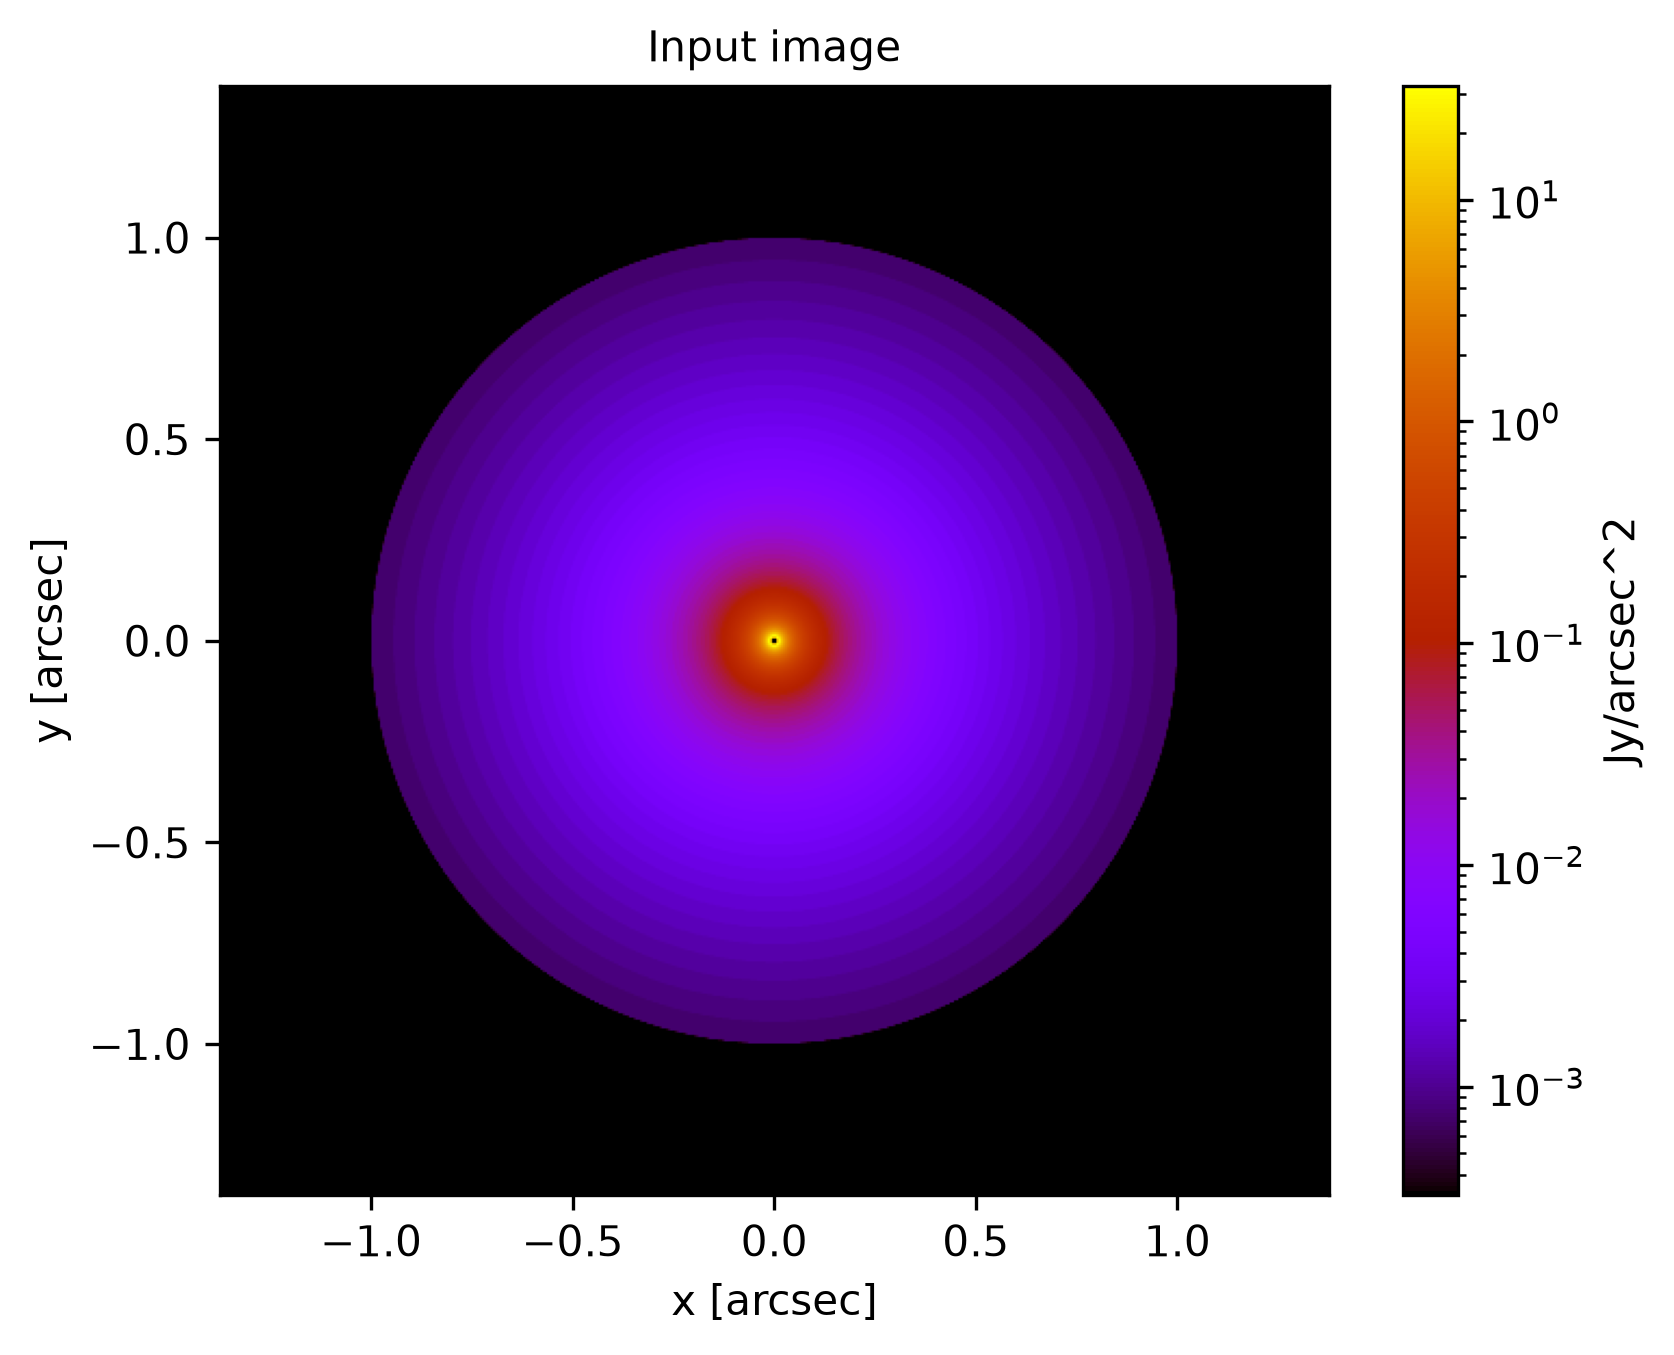

In [4]:
# Plot the preimage on a log colour scale; the image will auto-save to origin.png
toy_target.plot_origin(log=True)

**Which simulation method?** There are two:
* **circular**: exact and fast, but only when *both* the target and the coronagraph's PSFs are circularly symmetric about the star. It uses one row of PSFs and rotates the result.
* **spatial**: works for any target. Every pixel is spread by the PSF of its own position.

With `method = "auto"` (the default), the circular method is used when both are symmetric. The target's symmetry is measured, with tolerance `symmetry_tol`; the vortex model's PSFs are symmetric. Otherwise the spatial method is used, in *rotate* mode for symmetric PSFs and in *direct* mode otherwise. You can force a method with `[method] method` in the parameter file, or with the `method=` argument of `plot_final`, `contrast` and `planet_video`. You can also state the symmetry yourself with `[target] symmetric` and `[coronagraph] symmetric`.

`check_symmetry()` prints the measurement and the choice, and returns `(method, spatial_mode)`. The example disk is symmetric, so the circular method is used.

Expected output:
```
Method: circular (auto; target symmetric: asymmetry 0.13%, light in the corners 0% (tol 1%); PSFs symmetric: vortex model)
```

In [5]:
# Which method makes the final image? "auto" (the default) uses the circular method when the target and
# the PSFs are both circularly symmetric about the star, and the spatial method otherwise
method, spatial_mode = toy_target.check_symmetry()

Method: circular (auto; target symmetric: asymmetry 0.13%, light in the corners 0% (tol 1%); PSFs symmetric: vortex model)


**The final image through a charge-2 vortex coronagraph.** `plot_final` returns the image as a 2-D array in Jy/arcsec² and saves the figure. Here the linear scale shows best what the coronagraph does: the star and the dust next to it are removed, and the dust is brightest in a ring just outside the inner working angle.
* The first call for a charge computes that charge's PSFs, which takes about 1–2 min at 512 px. They are saved as `radial_vortex_c2_N512_range16_lyot0.95_frame734.npy` and reused.
* Options: `charge` (positive, even); `iwa_ignore=True` removes the dust inside the inner working angle; `add_planet=False` leaves out the planets; `method` / `spatial_mode`; `log=True` (the faint outer disk); `plot_dpi`; `flip`.

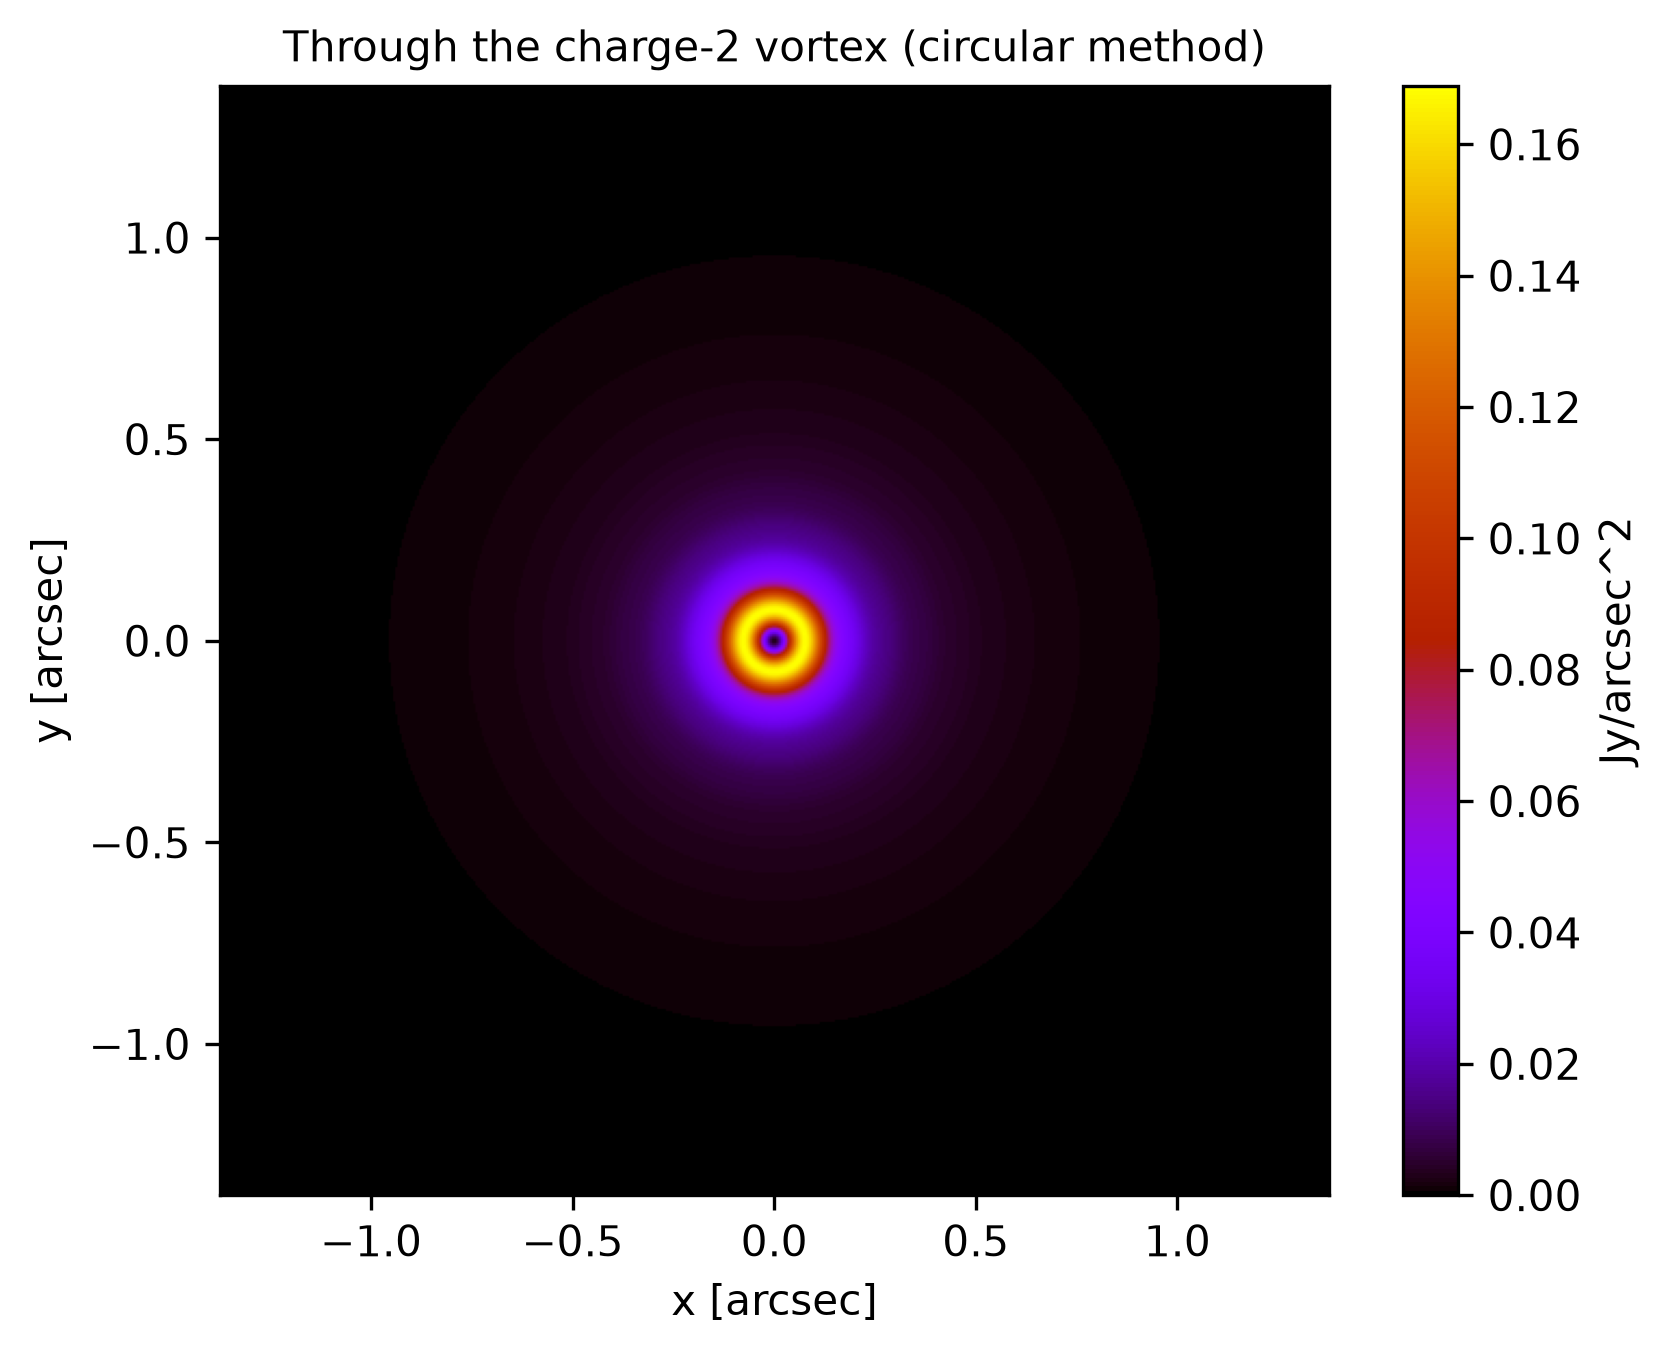

In [6]:
# Plot the final image through vortex coronagraph with charge = 2; the image will auto-save to charge2_final.png
# (the radial PSFs are computed once and cached in [compute] psf_cache_dir)
final_image = toy_target.plot_final(charge=2)

**Charge 6.** A higher charge blocks the star better, but over a larger region. Its inner working angle (IWA), the separation where an off-axis source keeps half of its light, is larger, so the bright ring moves out and the inner disk is dimmer than with charge 2.

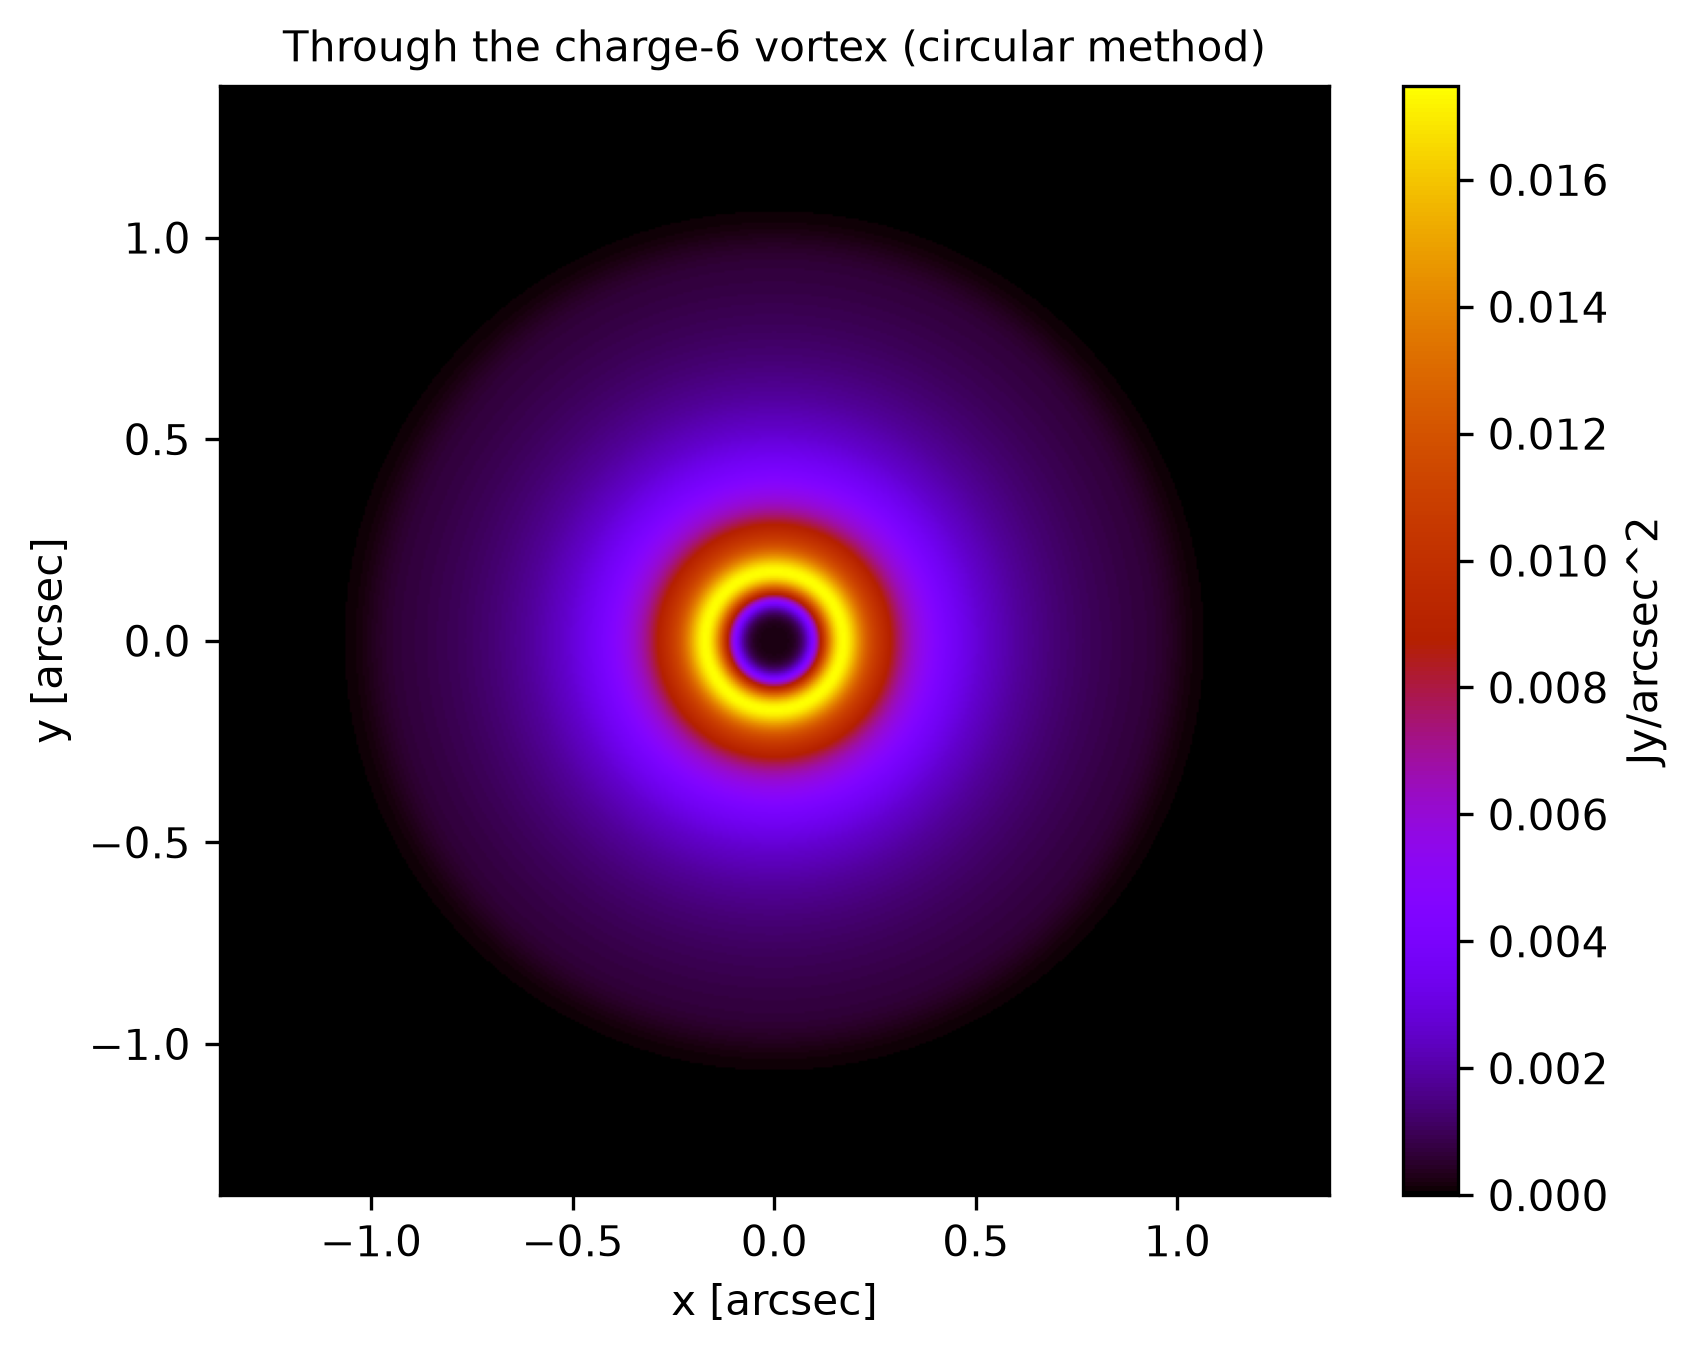

In [7]:
# Plot the final image through vortex coronagraph with charge = 6; the image will auto-save to charge6_final.png
final_image = toy_target.plot_final(charge=6)

## Planets

Planets are point sources added on top of the disk. Each planet's PSF is computed at its own position (in the circular method it is interpolated from the radial PSFs). Brightness is in Jy: at 1 µm a Sun-like star at 10 pc gives about 50 Jy, so the planets below (3-5e-5 Jy) have contrasts of about 1e-6, like young, self-luminous giant planets (a mature Jupiter in reflected light is about 1e-9). Three ways to give a position, with `mode`:
* `"cartesian"`: `pos=[x, y]` in arcsec (static planet);
* `"polar"`: `pos=[r, angle]`, with r in arcsec and the angle in degrees from the x axis (static planet);
* `"moving"` (the default): `pos=[a, e, position angle, inclination, t]`. These are the orbit's semi-major axis a (arcsec), eccentricity e, position angle and inclination (degrees), and the time t in orbital periods. Moving planets can be moved along their orbit with `planet_move` and animated with `planet_video`.

In [8]:
# Now add a static planet, where pos=(x_position, y_position) in arcsec
toy_target.add_planet(pos=[0.5,0], brightness=0.00005, mode="cartesian")

In [9]:
# You could also add a moving planet on an elliptic orbit, where pos=(length of the semi-major axis, eccentricity, position angle, inclination angle, time/period))
toy_target.add_planet(pos=[0.5,0.6,60,0,0.1], brightness=0.00003, mode="moving")

In [10]:
# Or a static planet in polar coordinates, where pos=(r in arcsec, angle in degrees)
toy_target.add_planet(pos=[0.3,45], brightness=0.00004, mode="polar")

The input image now marks the planets with their brightness in Jy, and the moving planet's orbit (dashed).

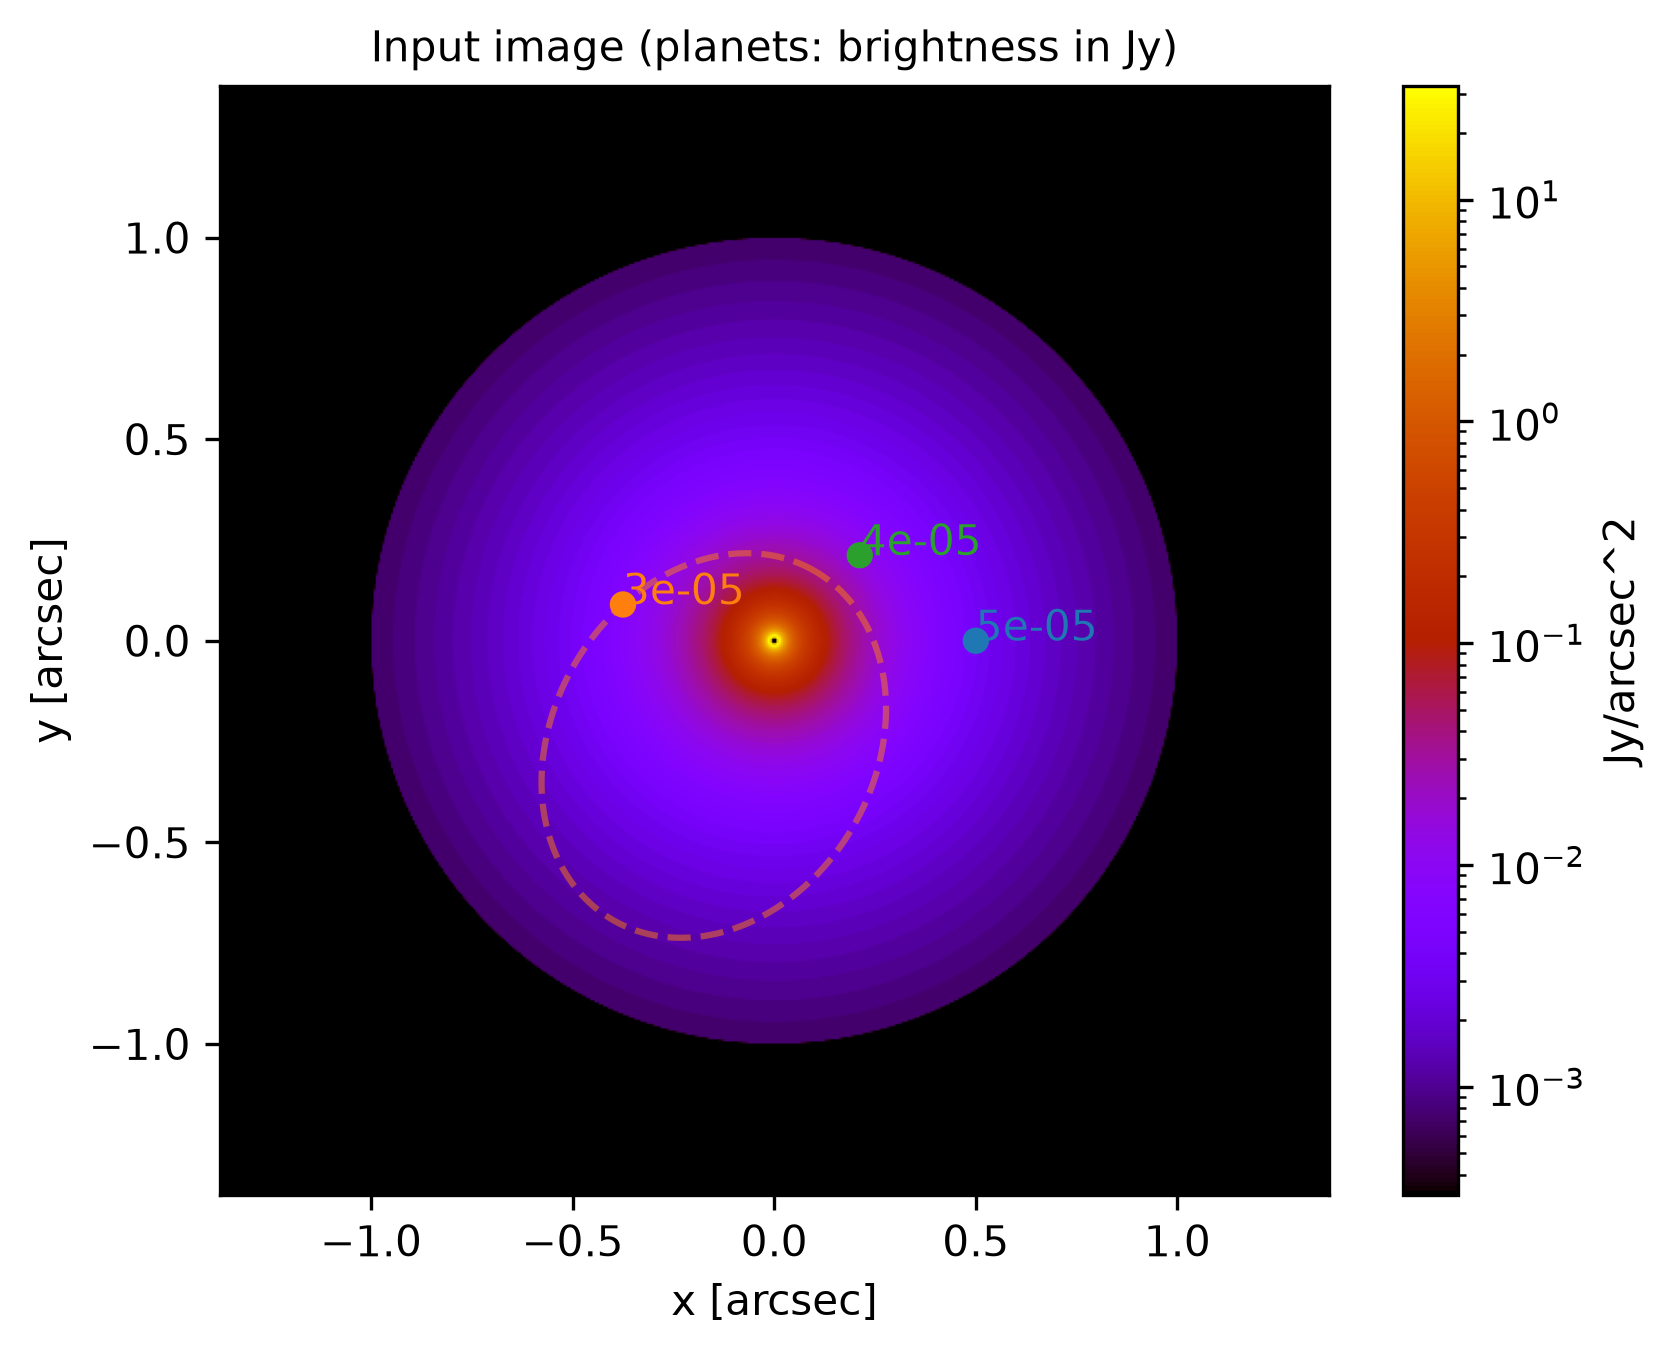

In [11]:
# Plot the preimage with planets; the image will auto-save to origin_with_planets.png
toy_target.plot_origin(log=True)

The final image with the planets. Each is a small bright spot on the dust; the one closest to the star (0.3 arcsec, near the bright ring) is the hardest to see.

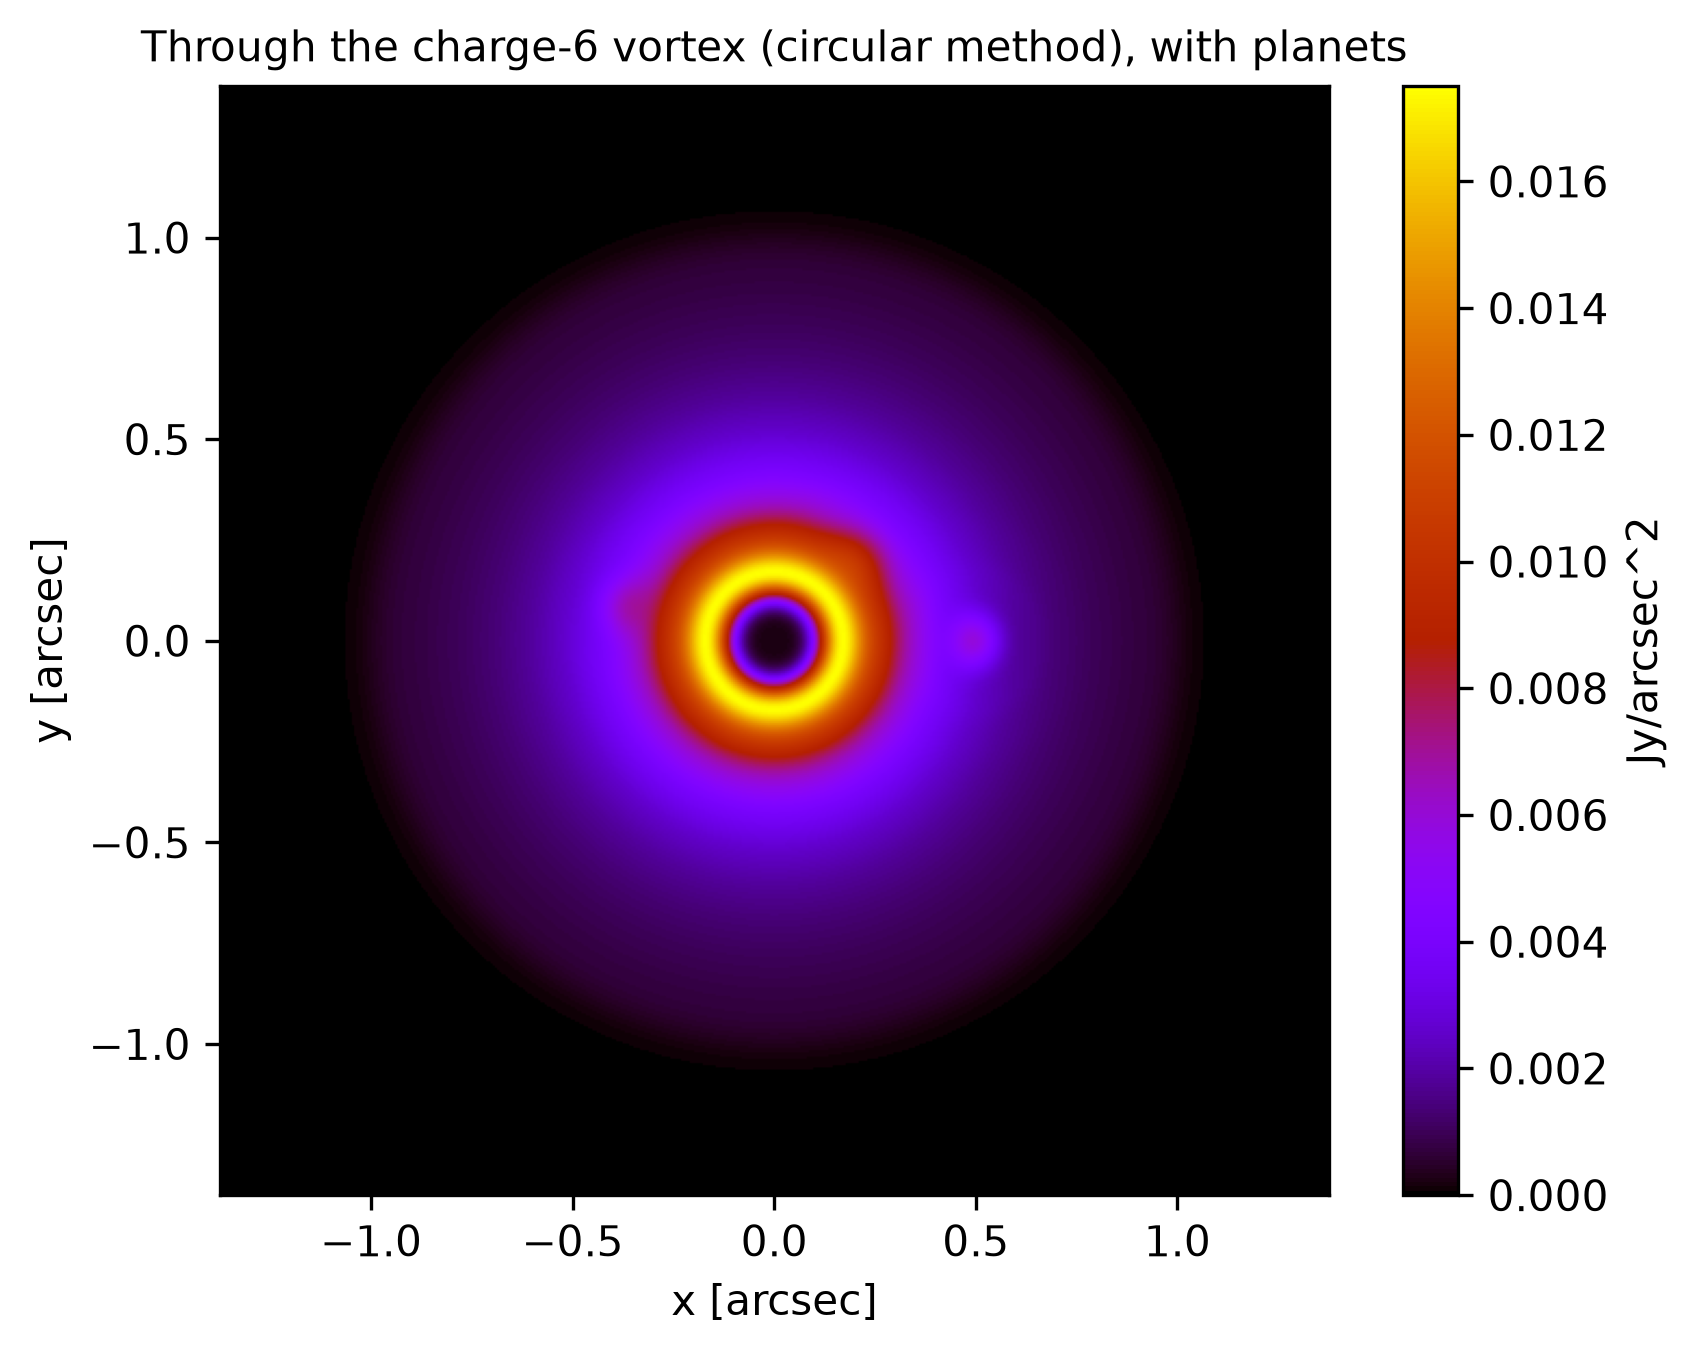

In [12]:
# Plot the final image with planets; the image will auto-save to charge6_with_planets_final.png
final_image = toy_target.plot_final(charge=6)

With `iwa_ignore=True`, the dust inside the inner working angle is removed before the simulation, to show how much of the image it makes: the bright ring around the centre is gone, and the planets stand out.

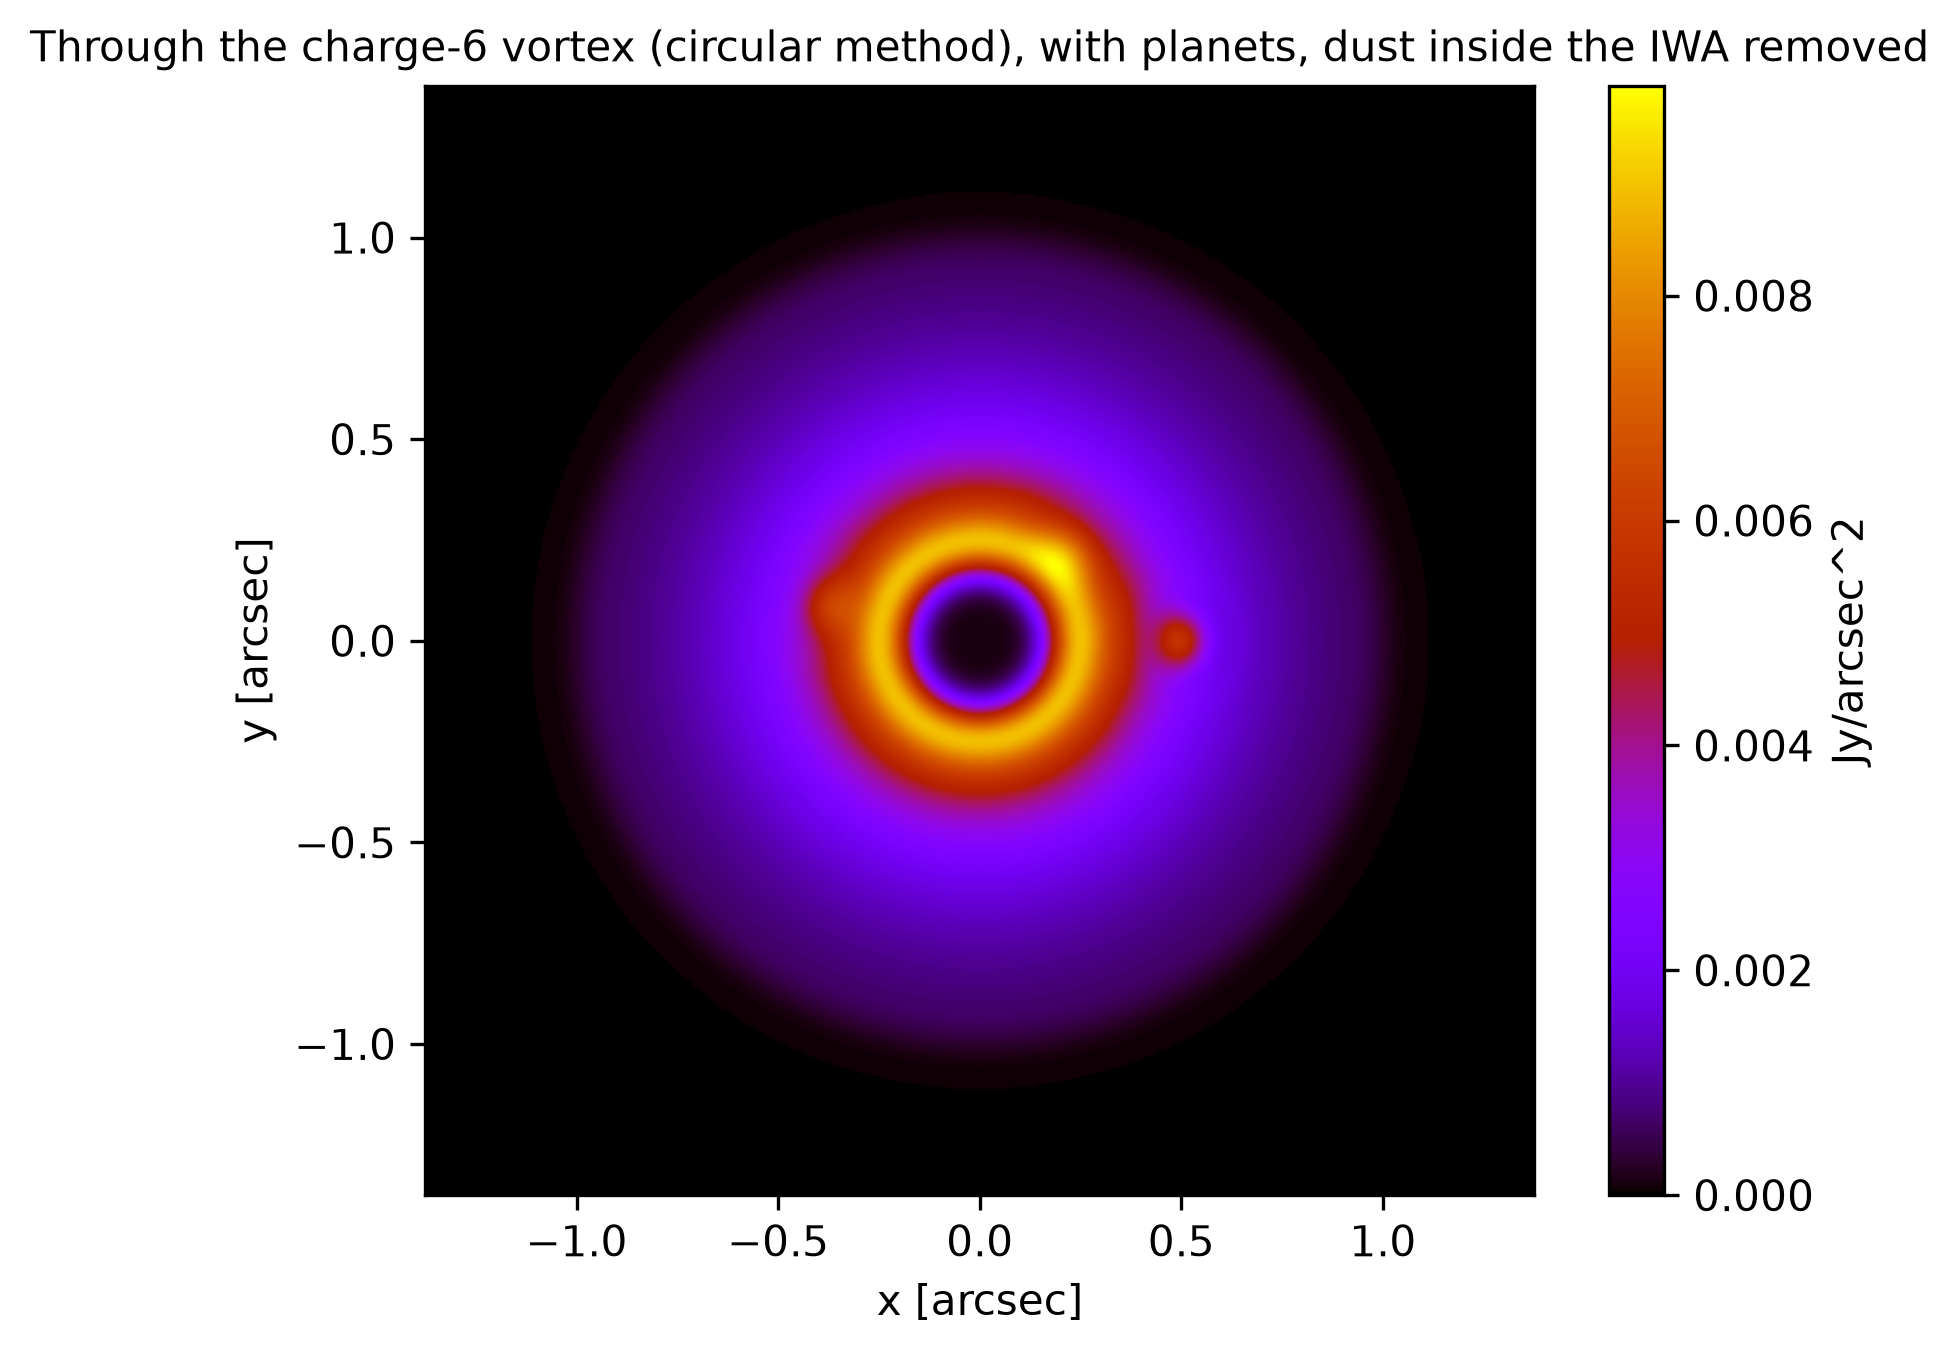

In [13]:
# Plot the final image by turning off the target inside IWA; the image will auto-save to charge6_with_planets_iwa_ignore_final.png
final_image = toy_target.plot_final(charge=6, iwa_ignore=True)

`list_planets()` prints each planet's current position (x, y in arcsec) and brightness. The `order` numbers used below are the numbers in this list.

Expected output:
```
Static Planet 1: (0.5, 0.0) arcsec, brightness: 5.00e-05 Jy
Moving Planet 2: (-0.3751700315402439, 0.08996213698601588) arcsec, brightness: 3.00e-05 Jy
Static Planet 3: (0.21213203435596426, 0.21213203435596423) arcsec, brightness: 4.00e-05 Jy
```

In [14]:
# List the planets
toy_target.list_planets()

Static Planet 1: (0.5, 0.0) arcsec, brightness: 5.00e-05 Jy
Moving Planet 2: (-0.3751700315402439, 0.08996213698601588) arcsec, brightness: 3.00e-05 Jy
Static Planet 3: (0.21213203435596426, 0.21213203435596423) arcsec, brightness: 4.00e-05 Jy


Delete planet 1; the others are renumbered.

Expected output:
```
Successfully remove planet #1, here is the latest planet list:
Moving Planet 1: (-0.3751700315402439, 0.08996213698601588) arcsec, brightness: 3.00e-05 Jy
Static Planet 2: (0.21213203435596426, 0.21213203435596423) arcsec, brightness: 4.00e-05 Jy
```

In [15]:
# Delete a specific planet
toy_target.delete_planet(order=1)

Successfully remove planet #1, here is the latest planet list:
Moving Planet 1: (-0.3751700315402439, 0.08996213698601588) arcsec, brightness: 3.00e-05 Jy
Static Planet 2: (0.21213203435596426, 0.21213203435596423) arcsec, brightness: 4.00e-05 Jy


Move a moving planet along its orbit by a time in orbital periods: `mode="cumulate"` (the default) adds the time, and `mode="specific"` sets it. `plot_pos=True` also plots the new position on the orbit. `plot_orbit` draws the orbit (as seen on the sky) with the planet's position.

Expected output:
```
Planet has moved to new position
```

In [16]:
# Move a moving planet on its orbit by time/period=0.1
toy_target.planet_move(time=0.1, order=1)

Planet has moved to new position


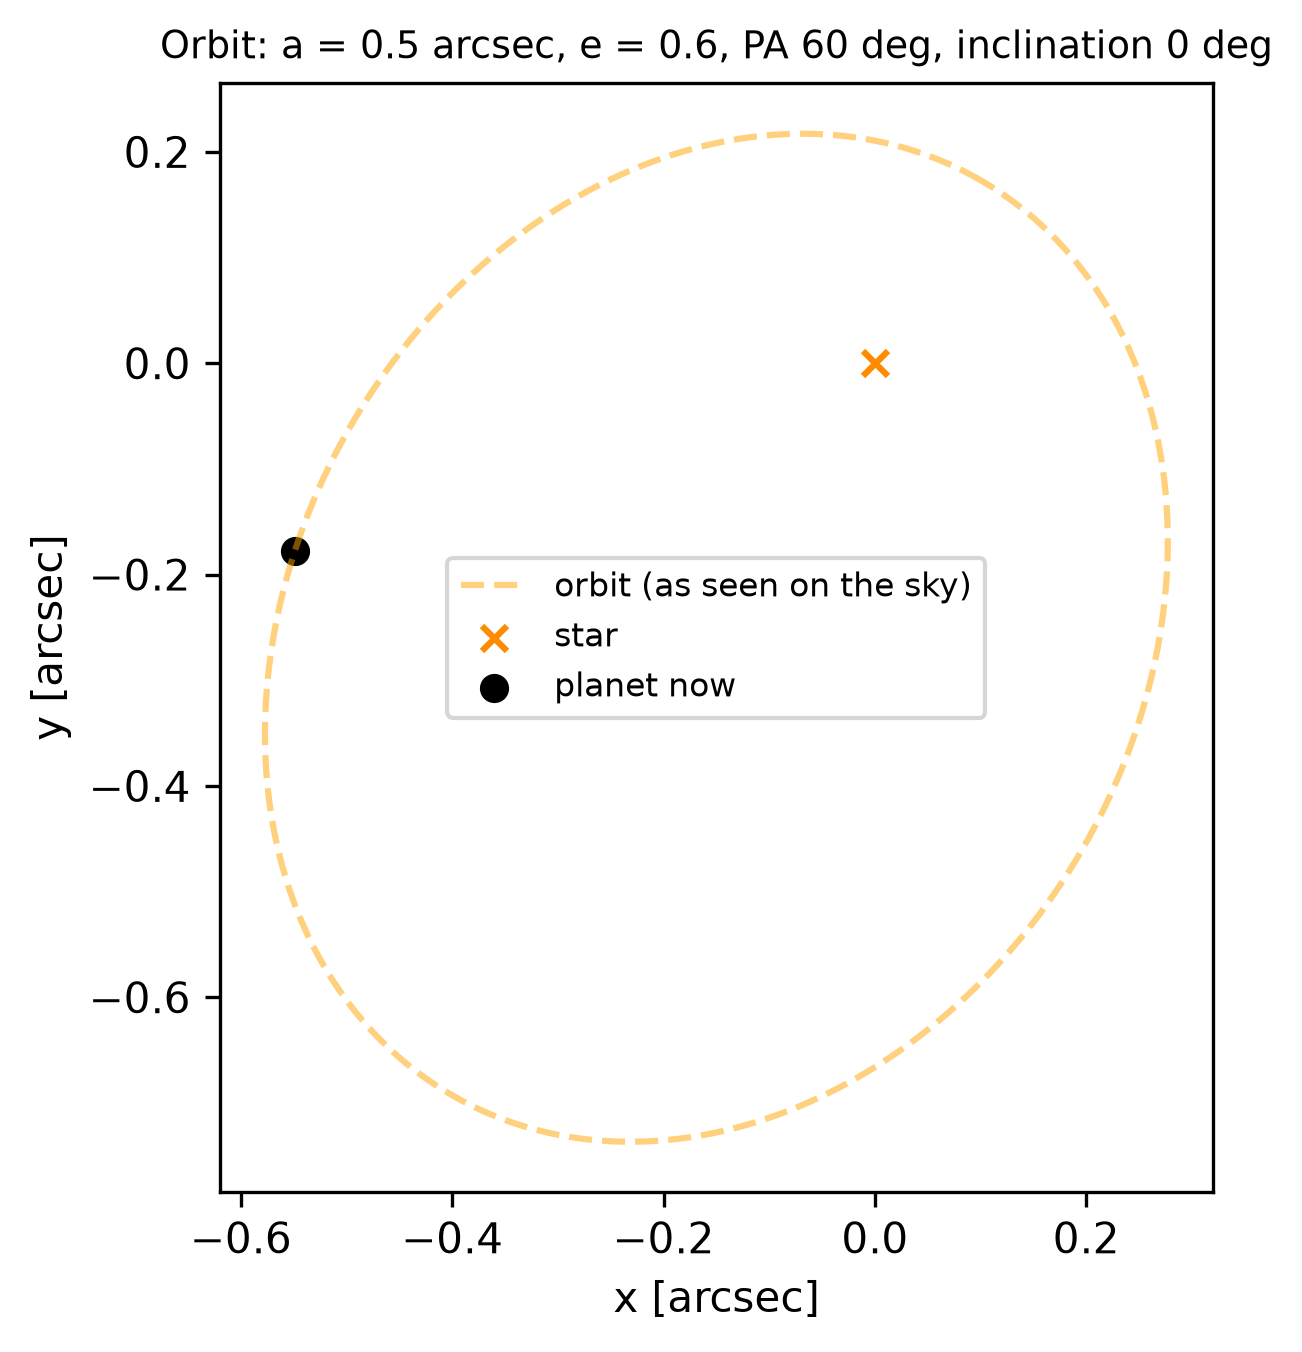

In [17]:
# Plot the orbit of a specific moving planet; the image will auto-save to oribit_planet#.png
toy_target.plot_orbit(order=1)

The input and the final image with the planet at its new position.

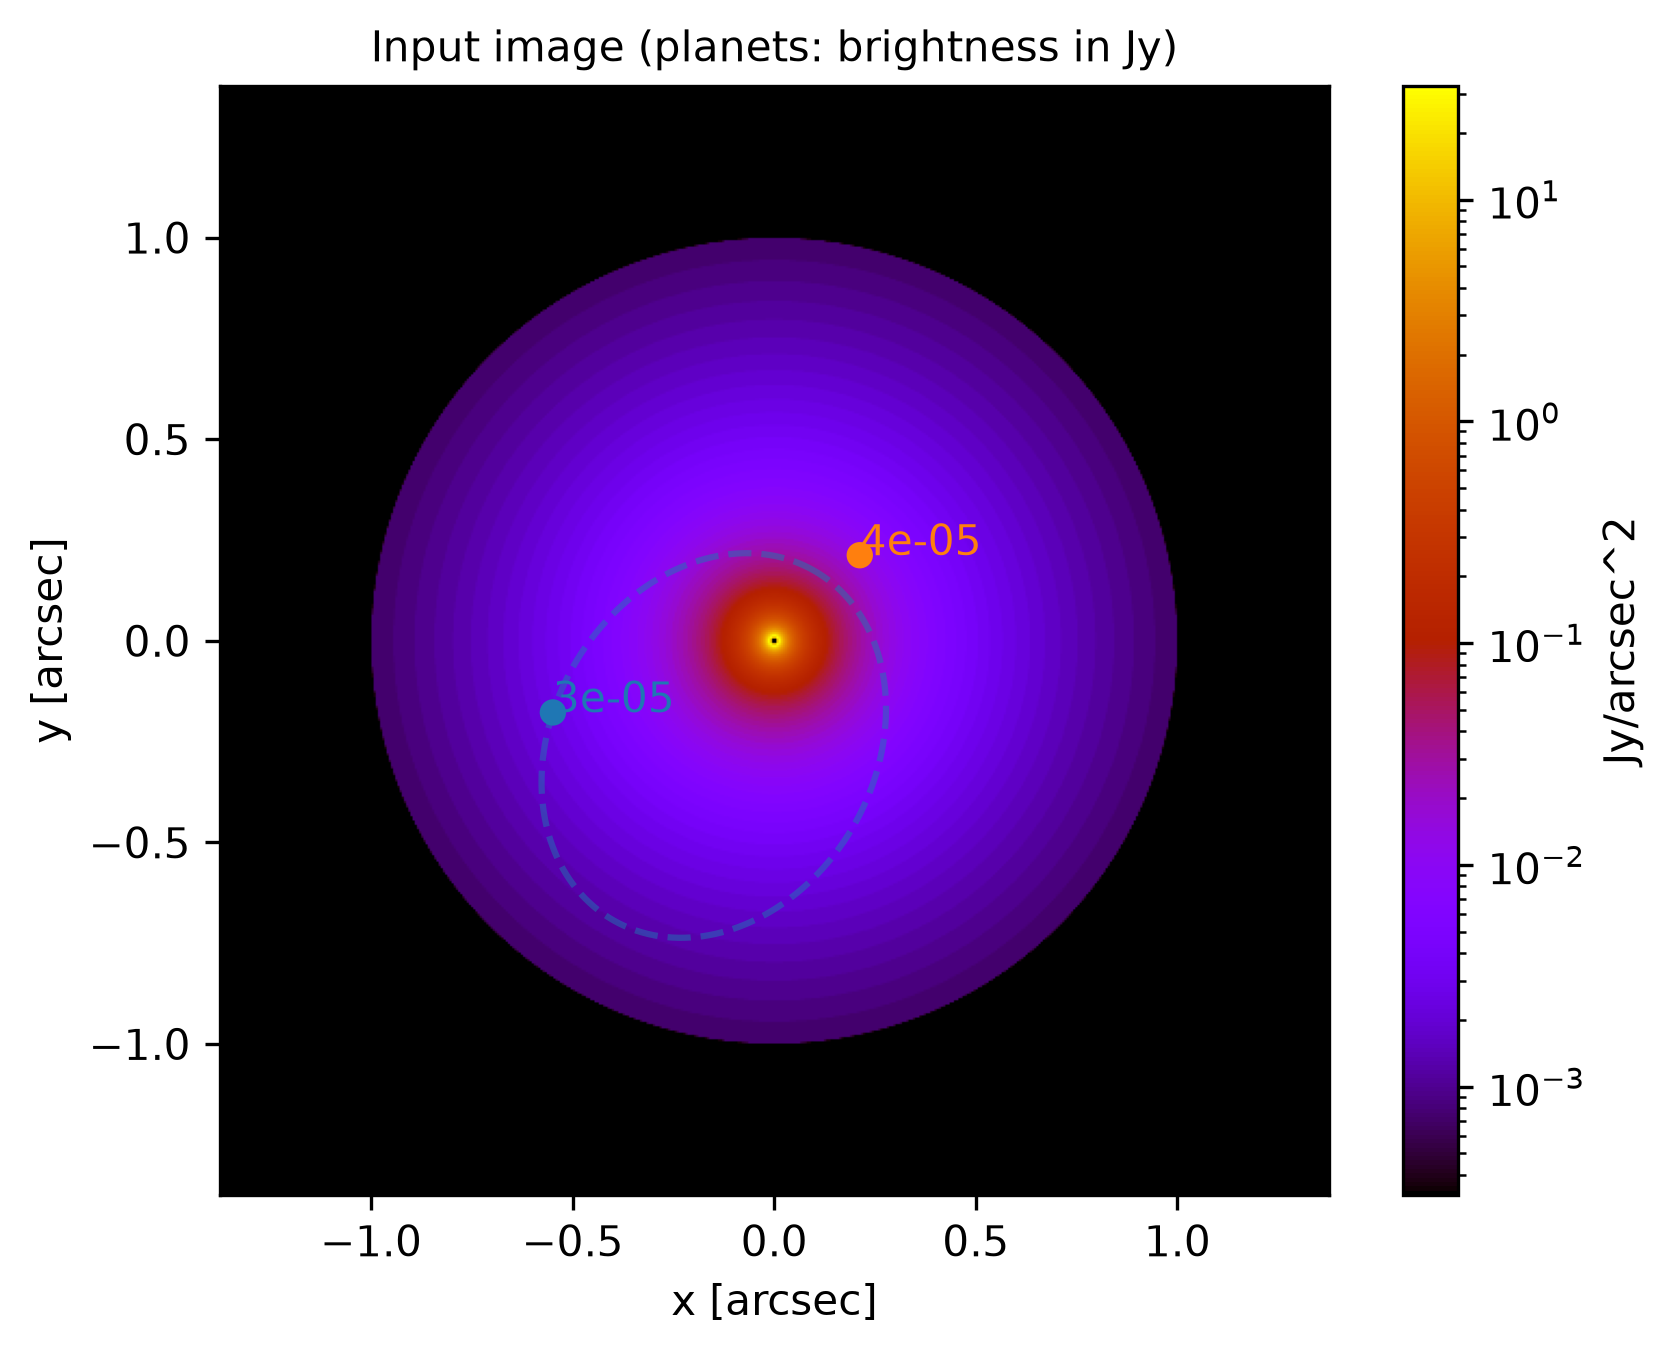

In [18]:
# Plot the new preimage with planets; the image will auto-save to origin_with_planets.png
toy_target.plot_origin(log=True)

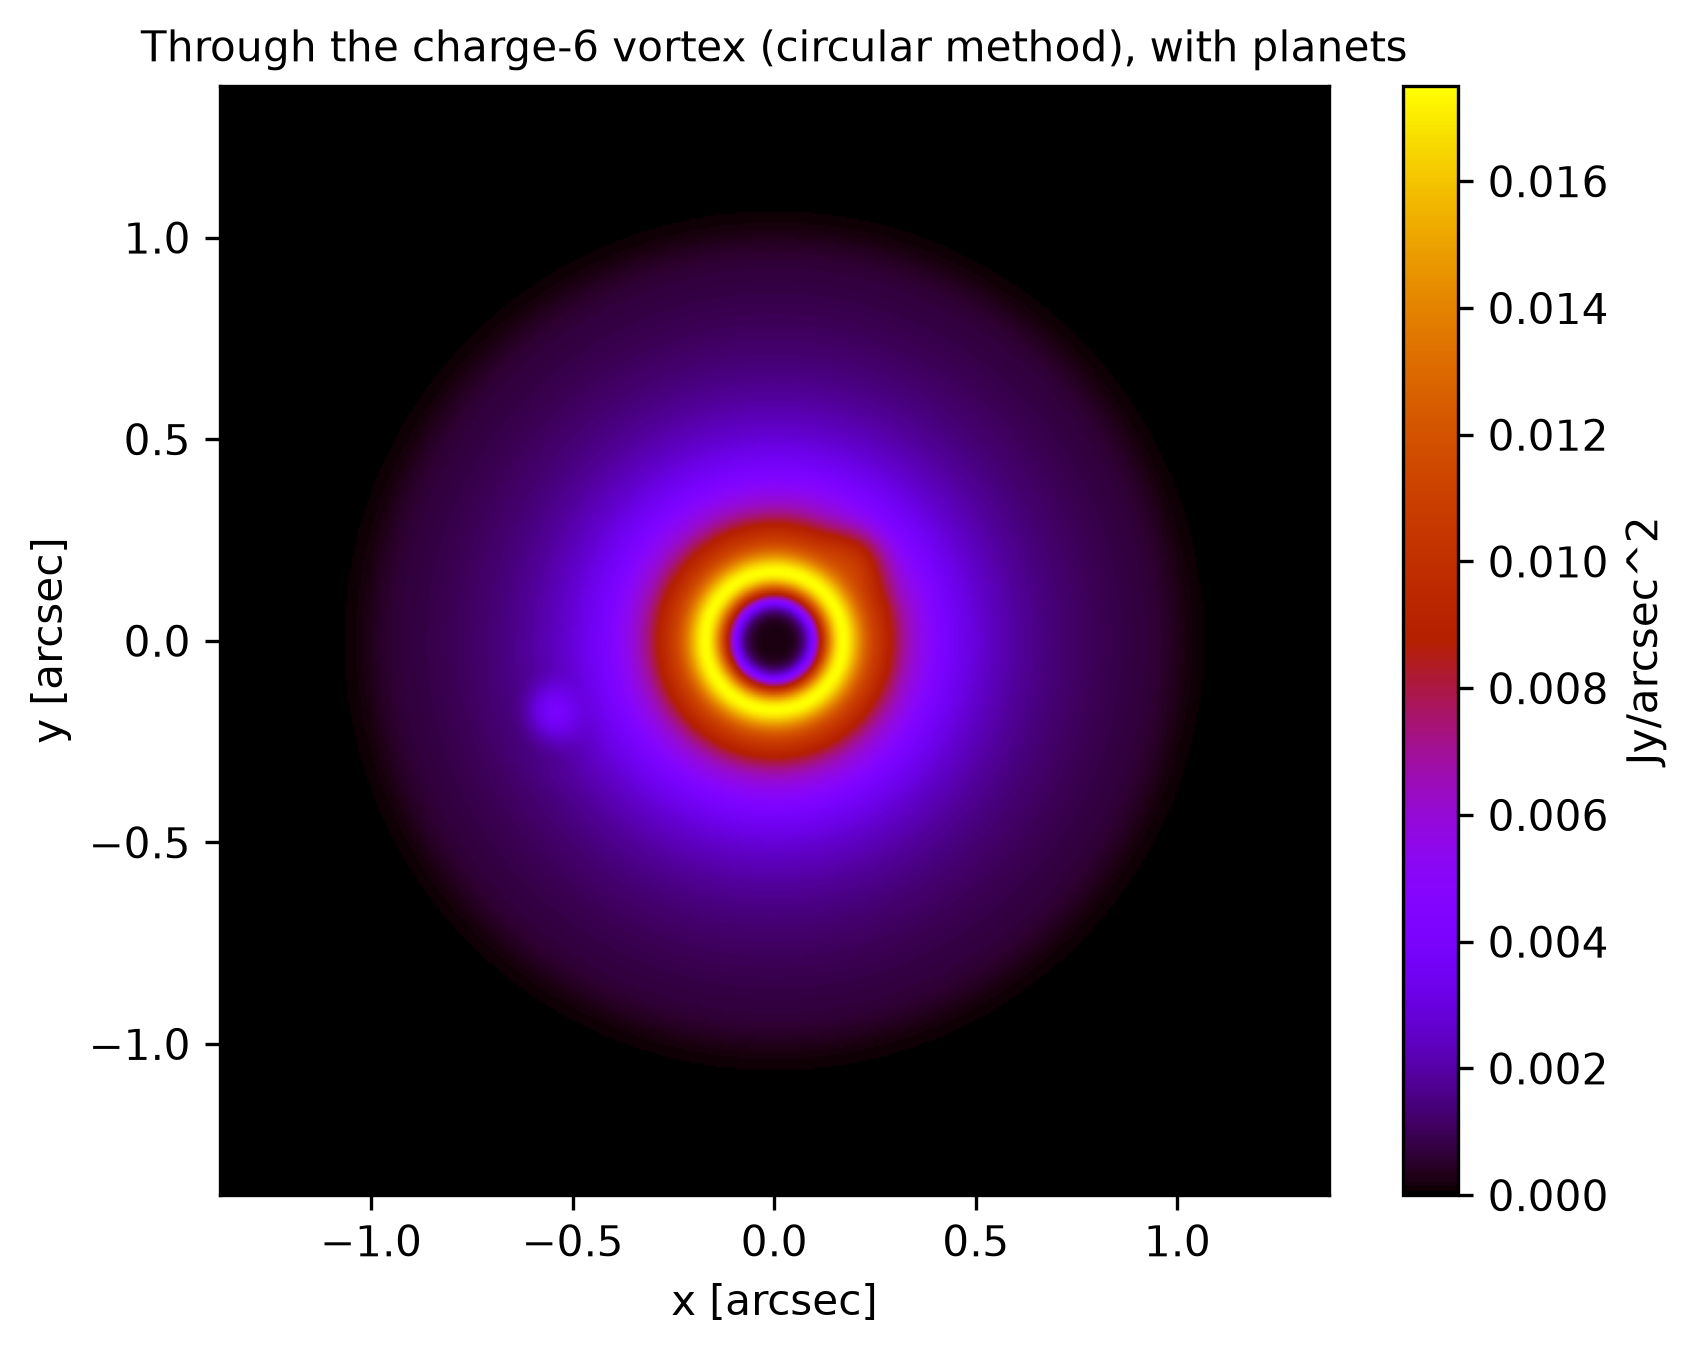

In [19]:
# Plot the new final image with planets; the image will auto-save to charge6_with_planets_final.png
final_image = toy_target.plot_final(charge=6)

## Contrast, throughput and videos

**Contrast**: how bright a planet is compared with the dust at the same place in the final image. The aperture is the planet's core (the pixels above half its peak). Inside it, `contrast` sums three things:
* the planet;
* the dust;
* the dust when the dust inside the inner working angle is ignored.

It returns them as a tuple (in Jy). It also plots the ratio of the dust to the planet in that core against a factor scaling the dust's brightness: 1 is this target as it is, 10 ten times more dust (e.g. a richer exozodiacal disk; up to `exozodi_limit`, default 10). Above the dotted line at 1 the dust outshines the planet. Use `plot_contrast=False` to skip the plot.

Expected output:
```
This is a charge-6 vortex coronagraph.
Planet brightness: 1.11e-05 Jy
Dust brightness: 1.68e-05 Jy
Dust brightness but ignore dust inside IWA: 1.64e-05 Jy
```

This is a charge-6 vortex coronagraph.


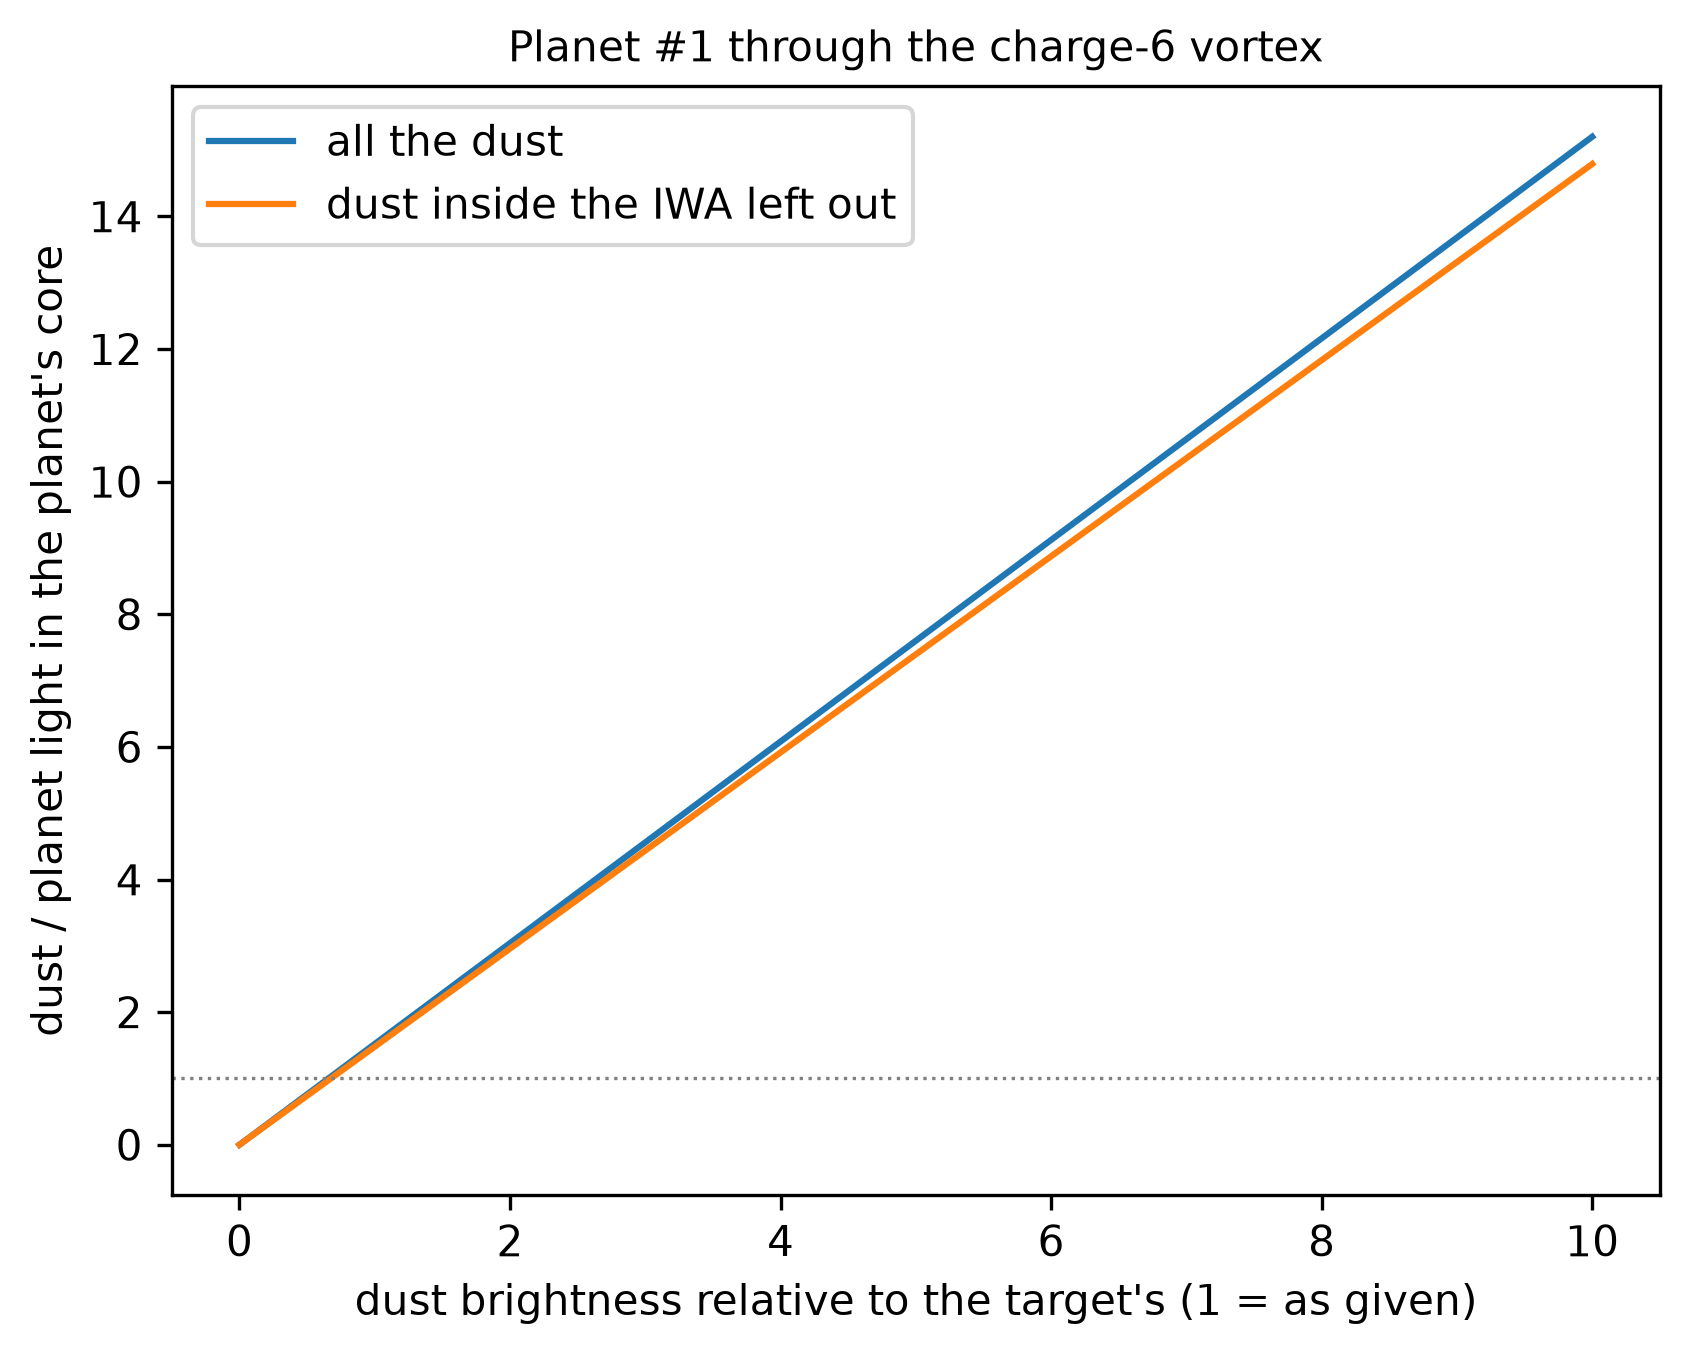

Planet brightness: 1.11e-05 Jy
Dust brightness: 1.68e-05 Jy
Dust brightness but ignore dust inside IWA: 1.64e-05 Jy


In [20]:
# Print a specific planet brightness, background brightness, and background brightness (ignored dust inside IWA)
# in the final image through vortex coronagraph with charge = 6 (also returned as a tuple)
planet_b, dust_b, dust_b_iwa = toy_target.contrast(charge=6, order=1)

**Core throughput**: the fraction of an off-axis source's light that stays in its PSF core after the coronagraph, against its distance from the star. The inner working angle (IWA) is where this reaches half its maximum. The radial PSFs used here are the ones cached by `plot_final`; `pixel_scale` (the image pixel in lambda/D) puts the distance in lambda/D (without it, in pixels).

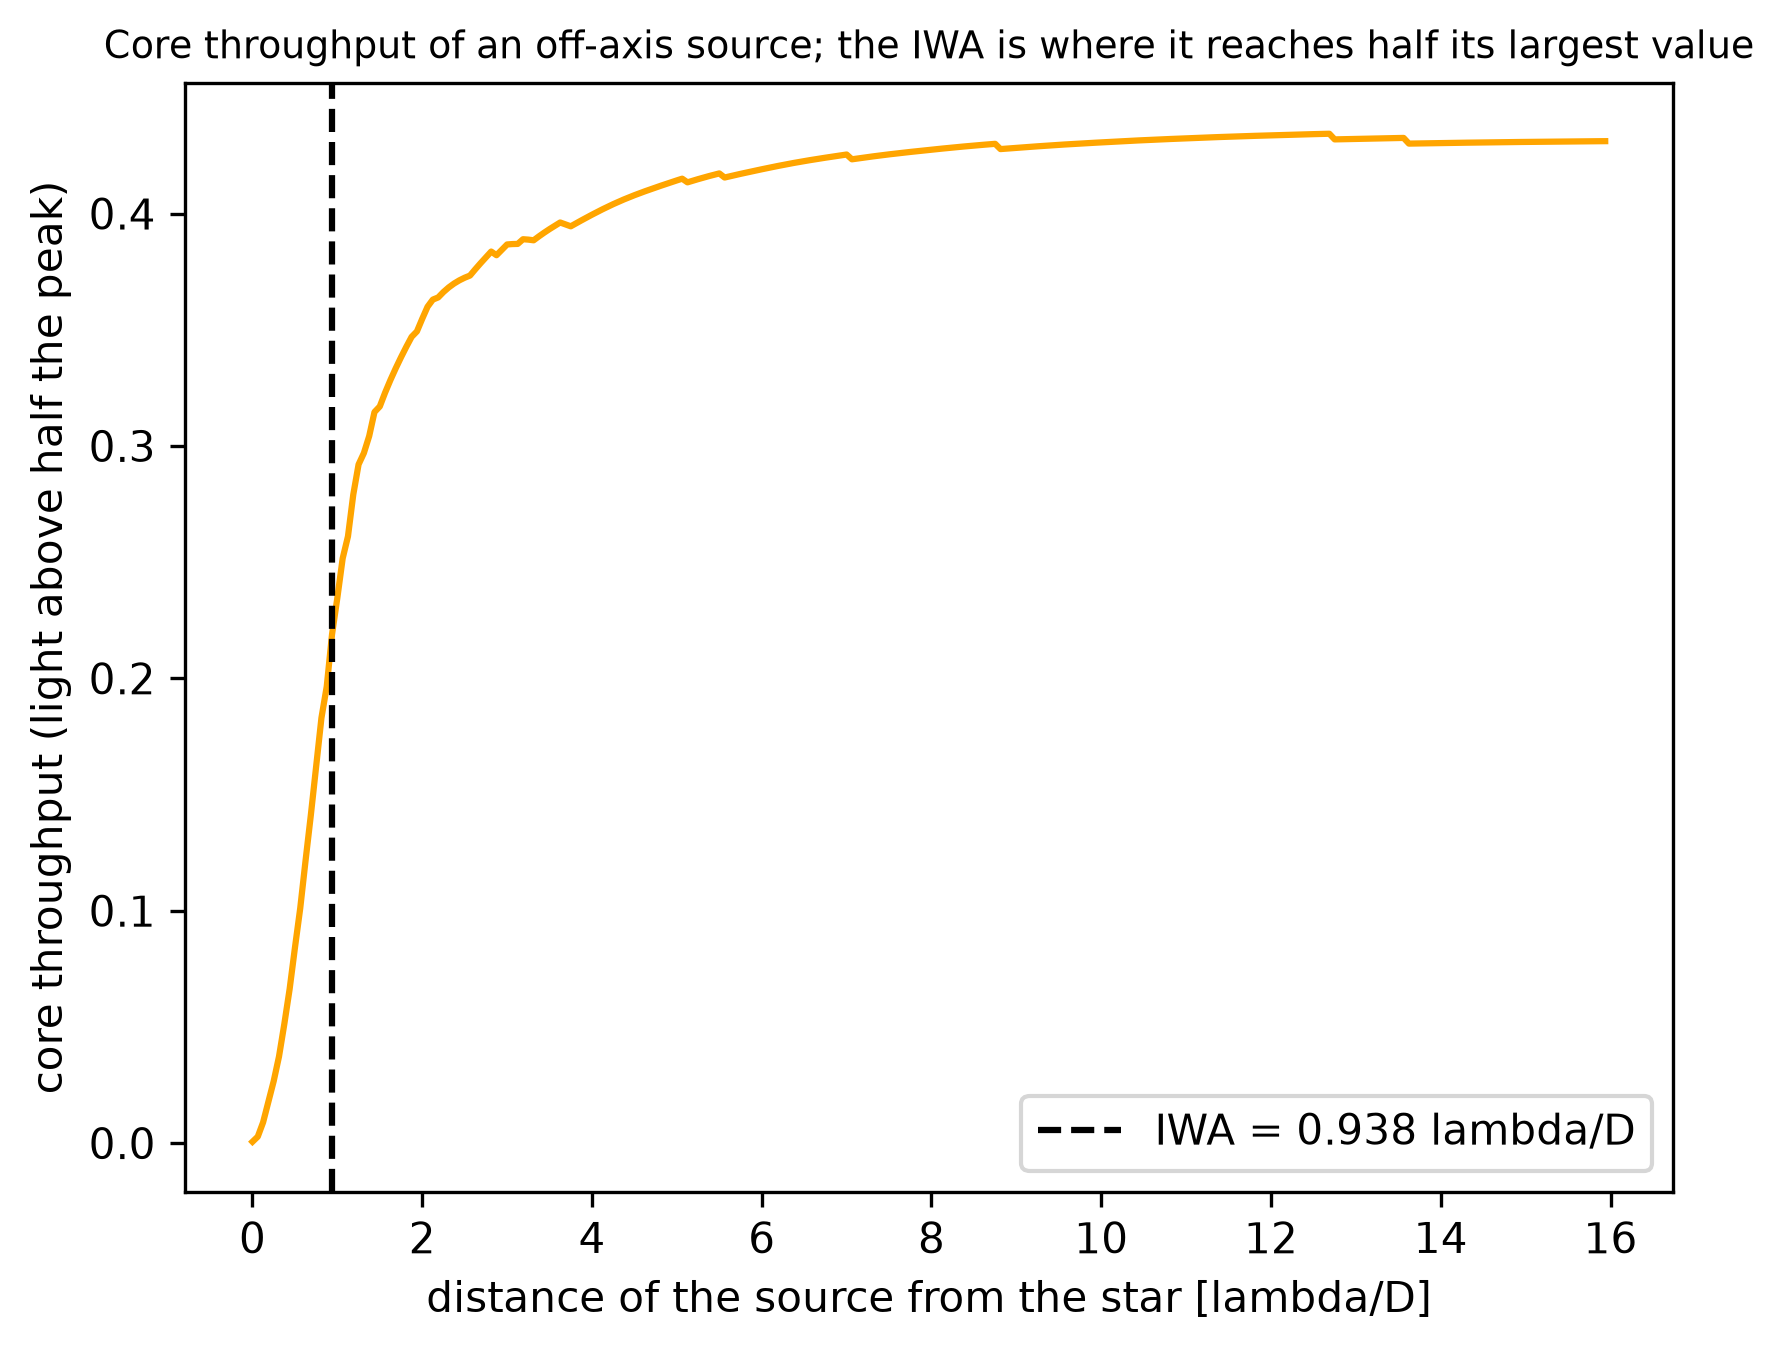

In [21]:
# Plot the core throughput and the inner working angle, in lambda/D
import toycoronagraph.psf as psf
psfs = toy_target.radial_psfs(charge=2)  # the radial PSFs (computed once, cached in psf_cache_dir)
lambda_d_per_pixel = 2*toy_target.par.psf_range/toy_target.par.target_pixel  # the image's pixel, in lambda/D
psf.cir_core_throughput_plot(psfs, pixel_scale=lambda_d_per_pixel)

**Planet video**: one orbital period of a moving planet over the final disk image. Options: `order`, `length` (seconds, default 3), `fps` (default 20), `iwa_ignore`, `method`, `plot_dpi`. A progress bar shows the frames being written. Afterwards the planet is back at its position. The videos are lossless WebM files: they play in VS Code, browsers and VLC.

In [22]:
# Make the planet movie; the video will be saved to planet_video.webm
toy_target.planet_video(charge=6)


planet_video.webm:   0%|          | 0/60 [00:00<?, ?it/s]


planet_video.webm:  17%|█▋        | 10/60 [00:02<00:10,  4.88it/s]


planet_video.webm:  35%|███▌      | 21/60 [00:04<00:07,  5.07it/s]


planet_video.webm:  53%|█████▎    | 32/60 [00:06<00:06,  4.45it/s]


planet_video.webm:  70%|███████   | 42/60 [00:10<00:04,  3.74it/s]


planet_video.webm:  83%|████████▎ | 50/60 [00:13<00:02,  3.42it/s]


planet_video.webm:  97%|█████████▋| 58/60 [00:15<00:00,  3.26it/s]


planet_video.webm: 100%|██████████| 60/60 [00:23<00:00,  2.60it/s]

Saved the video to planet_video.webm


In [23]:
# Make the planet movie again, but ignore the dust inside IWA; the video will be saved to planet_video_iwa_ignore.webm
toy_target.planet_video(charge=6, iwa_ignore=True)


planet_video_iwa_ignore.webm:   0%|          | 0/60 [00:00<?, ?it/s]


planet_video_iwa_ignore.webm:  17%|█▋        | 10/60 [00:02<00:11,  4.54it/s]


planet_video_iwa_ignore.webm:  33%|███▎      | 20/60 [00:04<00:09,  4.39it/s]


planet_video_iwa_ignore.webm:  48%|████▊     | 29/60 [00:06<00:07,  4.09it/s]


planet_video_iwa_ignore.webm:  63%|██████▎   | 38/60 [00:10<00:06,  3.42it/s]


planet_video_iwa_ignore.webm:  77%|███████▋  | 46/60 [00:13<00:04,  3.16it/s]


planet_video_iwa_ignore.webm:  88%|████████▊ | 53/60 [00:15<00:02,  3.14it/s]


planet_video_iwa_ignore.webm: 100%|██████████| 60/60 [00:18<00:00,  2.98it/s]


planet_video_iwa_ignore.webm: 100%|██████████| 60/60 [00:24<00:00,  2.43it/s]

Saved the video to planet_video_iwa_ignore.webm


## The spatial method

The spatial method works for any target. Each pixel's light is spread by the PSF of a source at that pixel, and nearby PSFs are blended smoothly. Only the PSF's shape is stored in a kernel of K x K pixels; the coronagraph's transmission at each pixel is applied separately.

How accurate it is follows `[method] error_target` (default 2%):
1. The kernel size K is chosen so that the light falling outside the kernel stays within 80% of the target, measured on PSFs of this target's brightest pixels.
2. The spacing of the PSF samples is chosen for the rest of the target.
3. An **error analysis** compares the result with exact PSFs at random positions. It covers each stage (kernel generation, blending between samples, the transmission map, the kernel crop) and the error end to end, per distance from the star.
4. Each image then gets its **estimated error**, weighted by where its light is.

The kernel size, the error analysis and the built model are saved with the PSFs (`kernel_*.json`, `error_*.npz`, `model_*.npz`), so a later run of the same image estimates nothing again, and a new session loads the model in about a second instead of building it (20 s here). A model file stores everything it was made from (the optics, mode, kernel size, error target, radial PSFs and the code) and is used only if all of it is the same; otherwise it is built again.

Here it is forced on the symmetric example, so it can be compared with the circular method; the two agree within the error target. The first call builds the PSFs, which takes about 5 min and about 1.7 GB of memory at 512 px (limit: `max_kernel_gb`). Later calls reuse them.

Expected output:
```
Method: spatial, rotate mode (set in the parameters; target symmetric: asymmetry 0.13%, ...)
Kernel size K=213 (+-6.6 lambda/D): estimated crop error 1.6% of the image light (80% of the 2% error target; 43 probe pixels)
rotate mode: 9495 PSF samples (5088 per-pixel within 2.52 lambda/D, 44 rings), K=213, kernel cube 1.72 GB
Spatial PSF error analysis vs exact PSFs (...):  [a table per stage and distance from the star]
Estimated error of this image (flux-weighted, from the PSF check): typical 1.8%, up to 2.9%; largest part: kernel crop (K=213) (1.7%)
```

Method: spatial, rotate mode (set in the parameters; target symmetric: asymmetry 0.13%, light in the corners 0% (tol 1%); PSFs symmetric: vortex model)
Kernel size K=213 (chosen for this image before: ./kernel_vortex_c6_N512_range16_lyot0.95_527f500819e3720d.json)


Spatial PSF model K=213: from ./model_vortex_c6_N512_range16_lyot0.95_rotate_K213_6e90666cb5d409c8.npz
Estimated error of this image (flux-weighted, from the PSF check): typical 1.8%, up to 2.9%; largest part: kernel crop (K=213) (1.7%)


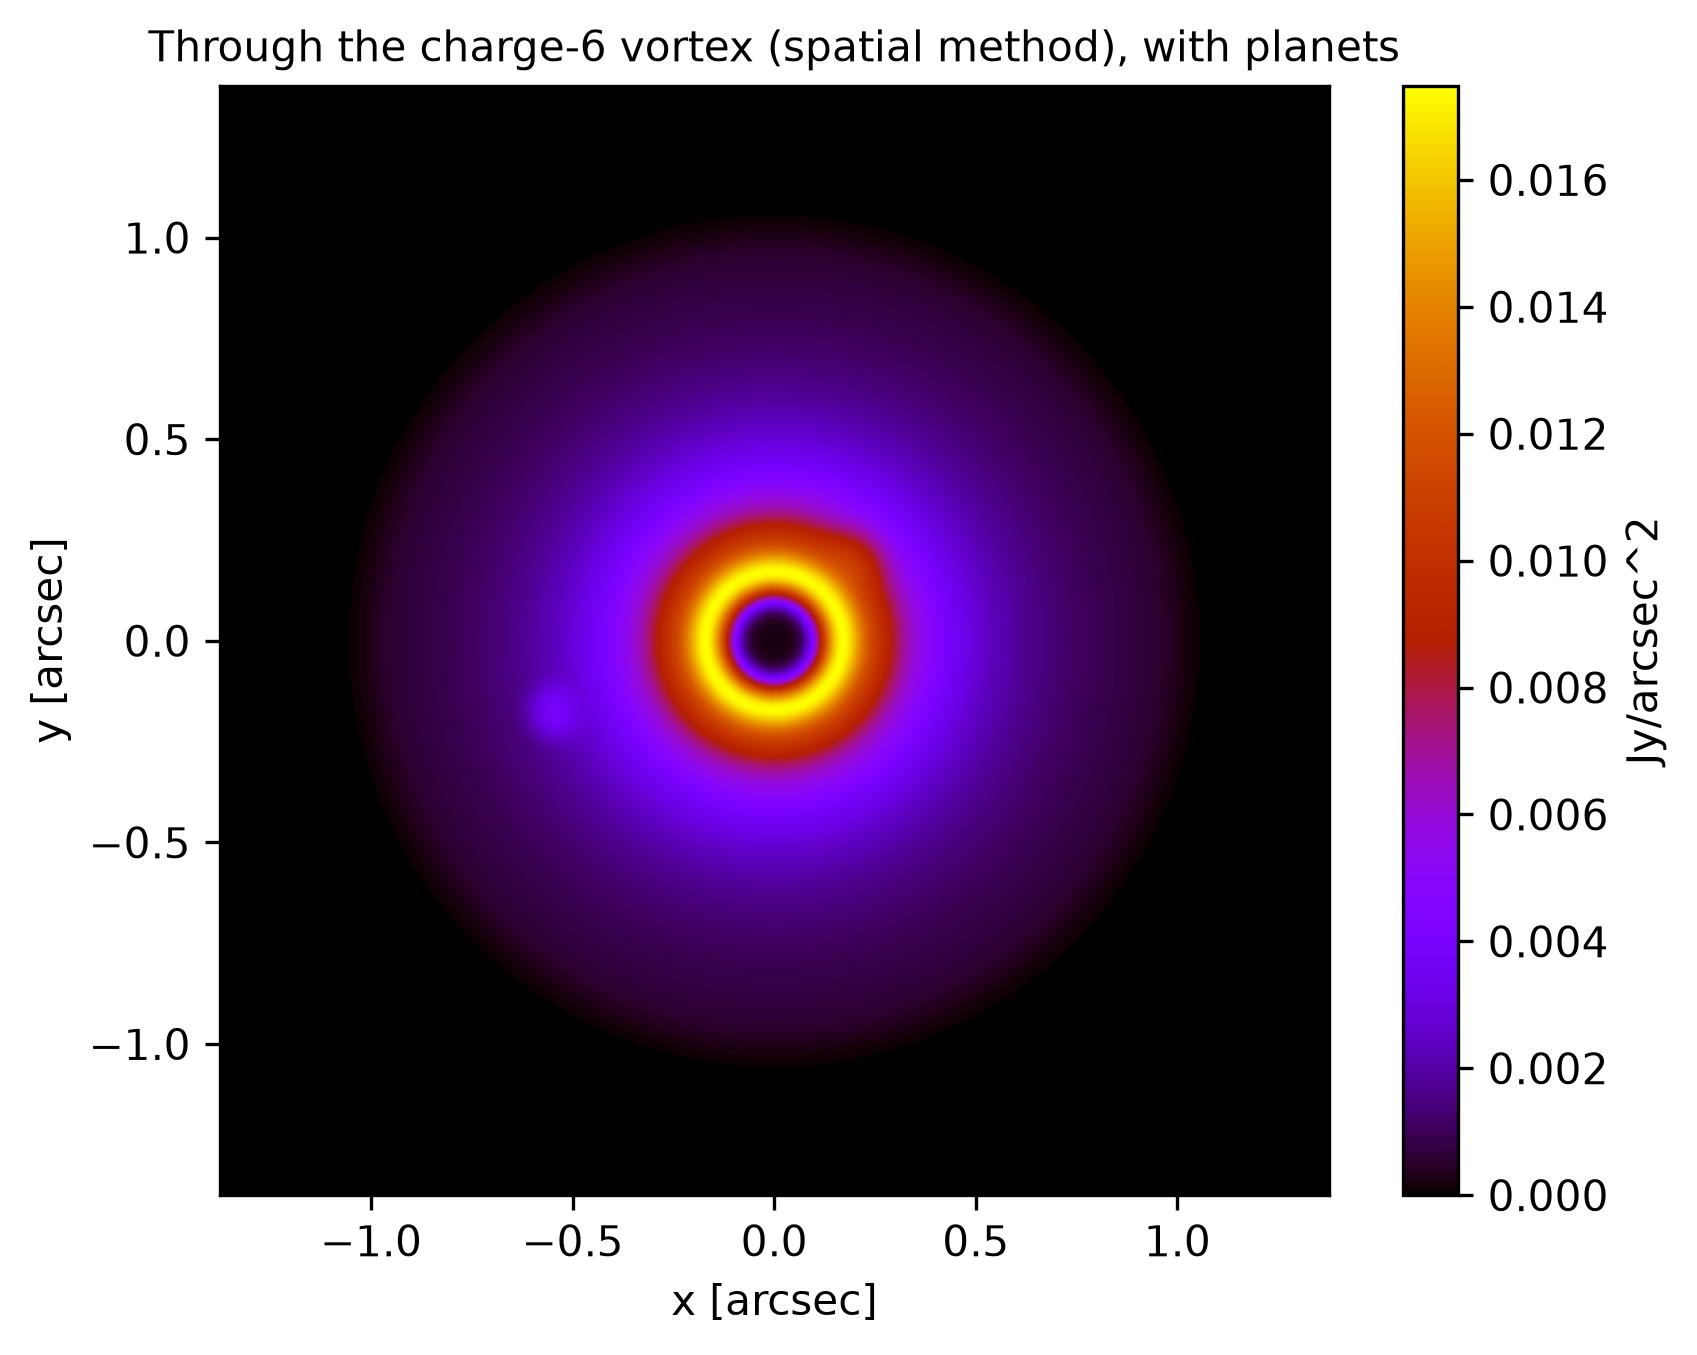

In [24]:
# The spatial method works for any target (it can also be set with method = "spatial" in the parameter
# file). It chooses the kernel size for [method] error_target, prints an error analysis per stage and the
# estimated error of each image; the image will auto-save to charge6_with_planets_spatial_final.png
final_image = toy_target.plot_final(charge=6, method="spatial")

The contrast with the spatial method. The planet's PSF is computed exactly at its position. The values agree with the circular method's within about 1%.

This is a charge-6 vortex coronagraph.


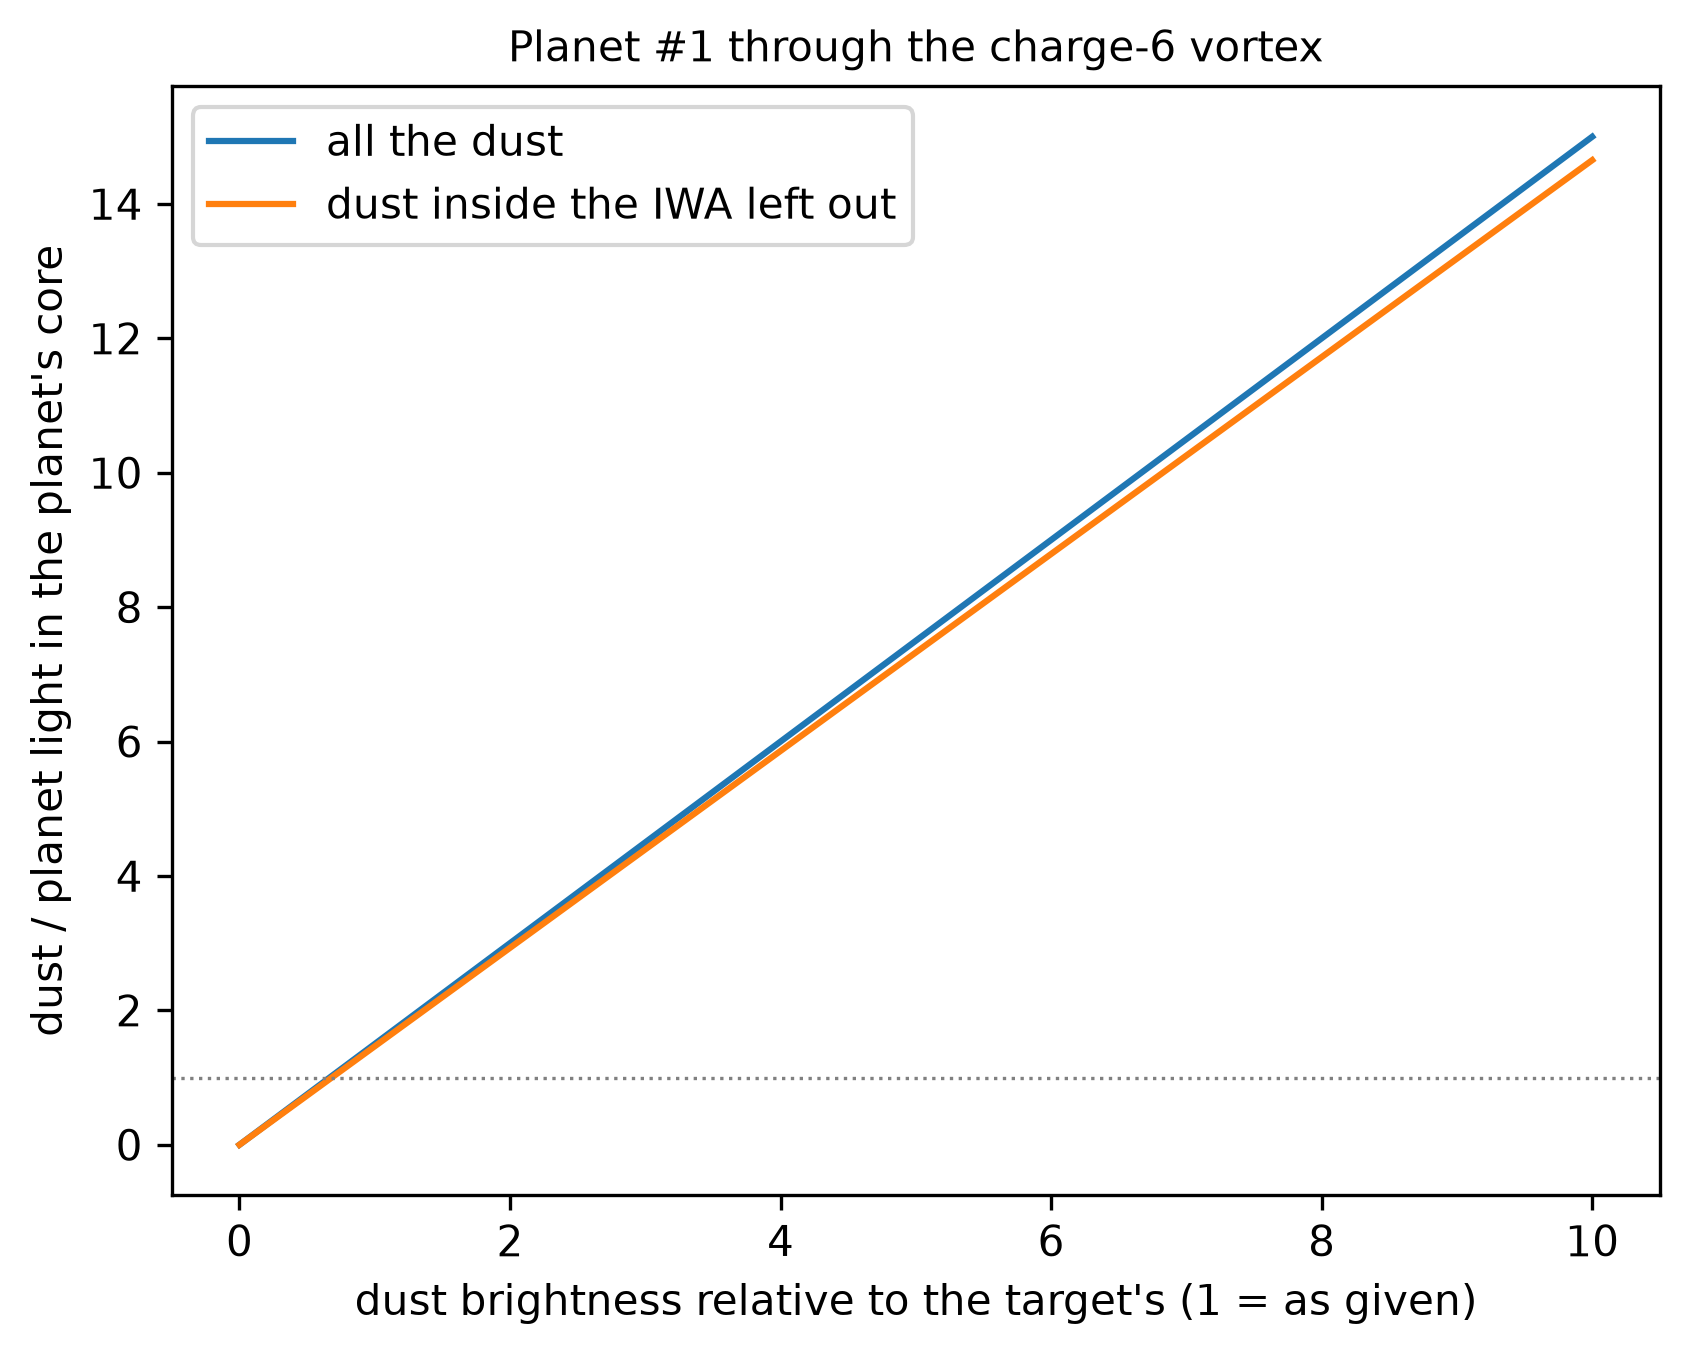

Planet brightness: 1.11e-05 Jy
Dust brightness: 1.66e-05 Jy
Dust brightness but ignore dust inside IWA: 1.62e-05 Jy


In [25]:
# Contrast with the spatial method (the planet PSF is computed exactly at the planet's position)
planet_b, dust_b, dust_b_iwa = toy_target.contrast(charge=6, order=1, method="spatial")

In [26]:
# Planet movie with the spatial method; the video will be saved to planet_video_spatial.webm
toy_target.planet_video(charge=6, method="spatial")


planet_video_spatial.webm:   0%|          | 0/60 [00:00<?, ?it/s]


planet_video_spatial.webm:   7%|▋         | 4/60 [00:02<00:28,  1.95it/s]


planet_video_spatial.webm:  15%|█▌        | 9/60 [00:04<00:24,  2.12it/s]


planet_video_spatial.webm:  23%|██▎       | 14/60 [00:06<00:21,  2.18it/s]


planet_video_spatial.webm:  32%|███▏      | 19/60 [00:08<00:18,  2.26it/s]

...


planet_video_spatial.webm:  90%|█████████ | 54/60 [00:31<00:04,  1.38it/s]


planet_video_spatial.webm:  95%|█████████▌| 57/60 [00:33<00:02,  1.35it/s]


planet_video_spatial.webm: 100%|██████████| 60/60 [00:36<00:00,  1.31it/s]


planet_video_spatial.webm: 100%|██████████| 60/60 [00:46<00:00,  1.30it/s]

Saved the video to planet_video_spatial.webm


## Your own target: an MCFOST disk

An MCFOST image cube (`RT.fits.gz` in MCFOST's `data_<wavelength>/` folder) can be used directly: a `[[source]]` with `kind = "mcfost"` and its `file`. The cube is recognized, and the unit, pixel scale and wavelength come from its header. Choose the image with:
* `component`: `"disk"` (everything but the star: total minus the direct starlight; the default), `"scattered_star"`, `"direct_thermal"`, `"scattered_thermal"`, `"Q"`, `"U"`, `"V"`, `"direct_star"` or `"total"`. Avoid `"total"`: it includes the star itself, which outshines the disk. It is the coronagraph's job to remove the star, and it isn't part of the target.
* `inclination`, `azimuth`: indices along the cube's inclination and azimuth axes (default 0).

`example_data/` holds a series of these models: `<inclination>_<wavelength in nm>.fits` for inclinations 0–85° at 575, 660, 730 and 825 nm, each with one inclination. Here the disk is at 45°, which is not circularly symmetric. The parameter file is written from the code so the example runs by itself; normally you would edit a `.toml` file.

Expected output:
```
Input: 45_575.fits (MCFOST disk, inclination 0, azimuth 0), 455 x 455, W/m^2/pixel; 0.006044 arcsec/pixel (header CDELT2 (deg) of 45_575.fits) = 55.65 lambda/D across at 5.75e-07 m (header WAVE (um) of 45_575.fits)
```

In [27]:
# An MCFOST image cube can be used directly. Here: the example disk at 45 degrees inclination, 575 nm
# (not circularly symmetric). The unit, pixel scale and wavelength come from its FITS header; the
# plane is chosen with component (and inclination / azimuth). Use "disk" (the total minus the direct
# starlight) or "scattered_star": the "total" plane includes the star itself, which outshines the disk,
# and the coronagraph is there to remove it.
from toycoronagraph import DATADIR
with open("inclined_disk.toml", "w") as f:
    f.write('[[source]]\nkind = "mcfost"\nfile = "%s45_575"\ncomponent = "disk"\n' % DATADIR)
disk = toy.Target(para_file="inclined_disk.toml")

Input: 45_575.fits (MCFOST disk, inclination 0, azimuth 0), 455 x 455, W/m^2/pixel; 0.006044 arcsec/pixel (header CDELT2 (deg) of 45_575.fits) = 55.65 lambda/D across at 5.75e-07 m (header WAVE (um) of 45_575.fits)


The inclined disk is far from symmetric (asymmetry 70%), so `auto` uses the spatial method.

Expected output:
```
Method: spatial, rotate mode (auto; target not symmetric: asymmetry 70%, light in the corners 0% (tol 1%); PSFs symmetric: vortex model)
```

In [28]:
# The target is not circularly symmetric, so "auto" uses the spatial method
method, spatial_mode = disk.check_symmetry()

Method: spatial, rotate mode (auto; target not symmetric: asymmetry 70%, light in the corners 0% (tol 1%); PSFs symmetric: vortex model)


The input (log scale) and the final image. The first `plot_final` for this target builds its PSFs, which takes about 5 min (K=131, typical error 1.7%). Unlike the face-on example, the result is not symmetric: the near side of the disk, which scatters more light forward towards us, is much brighter near the star.

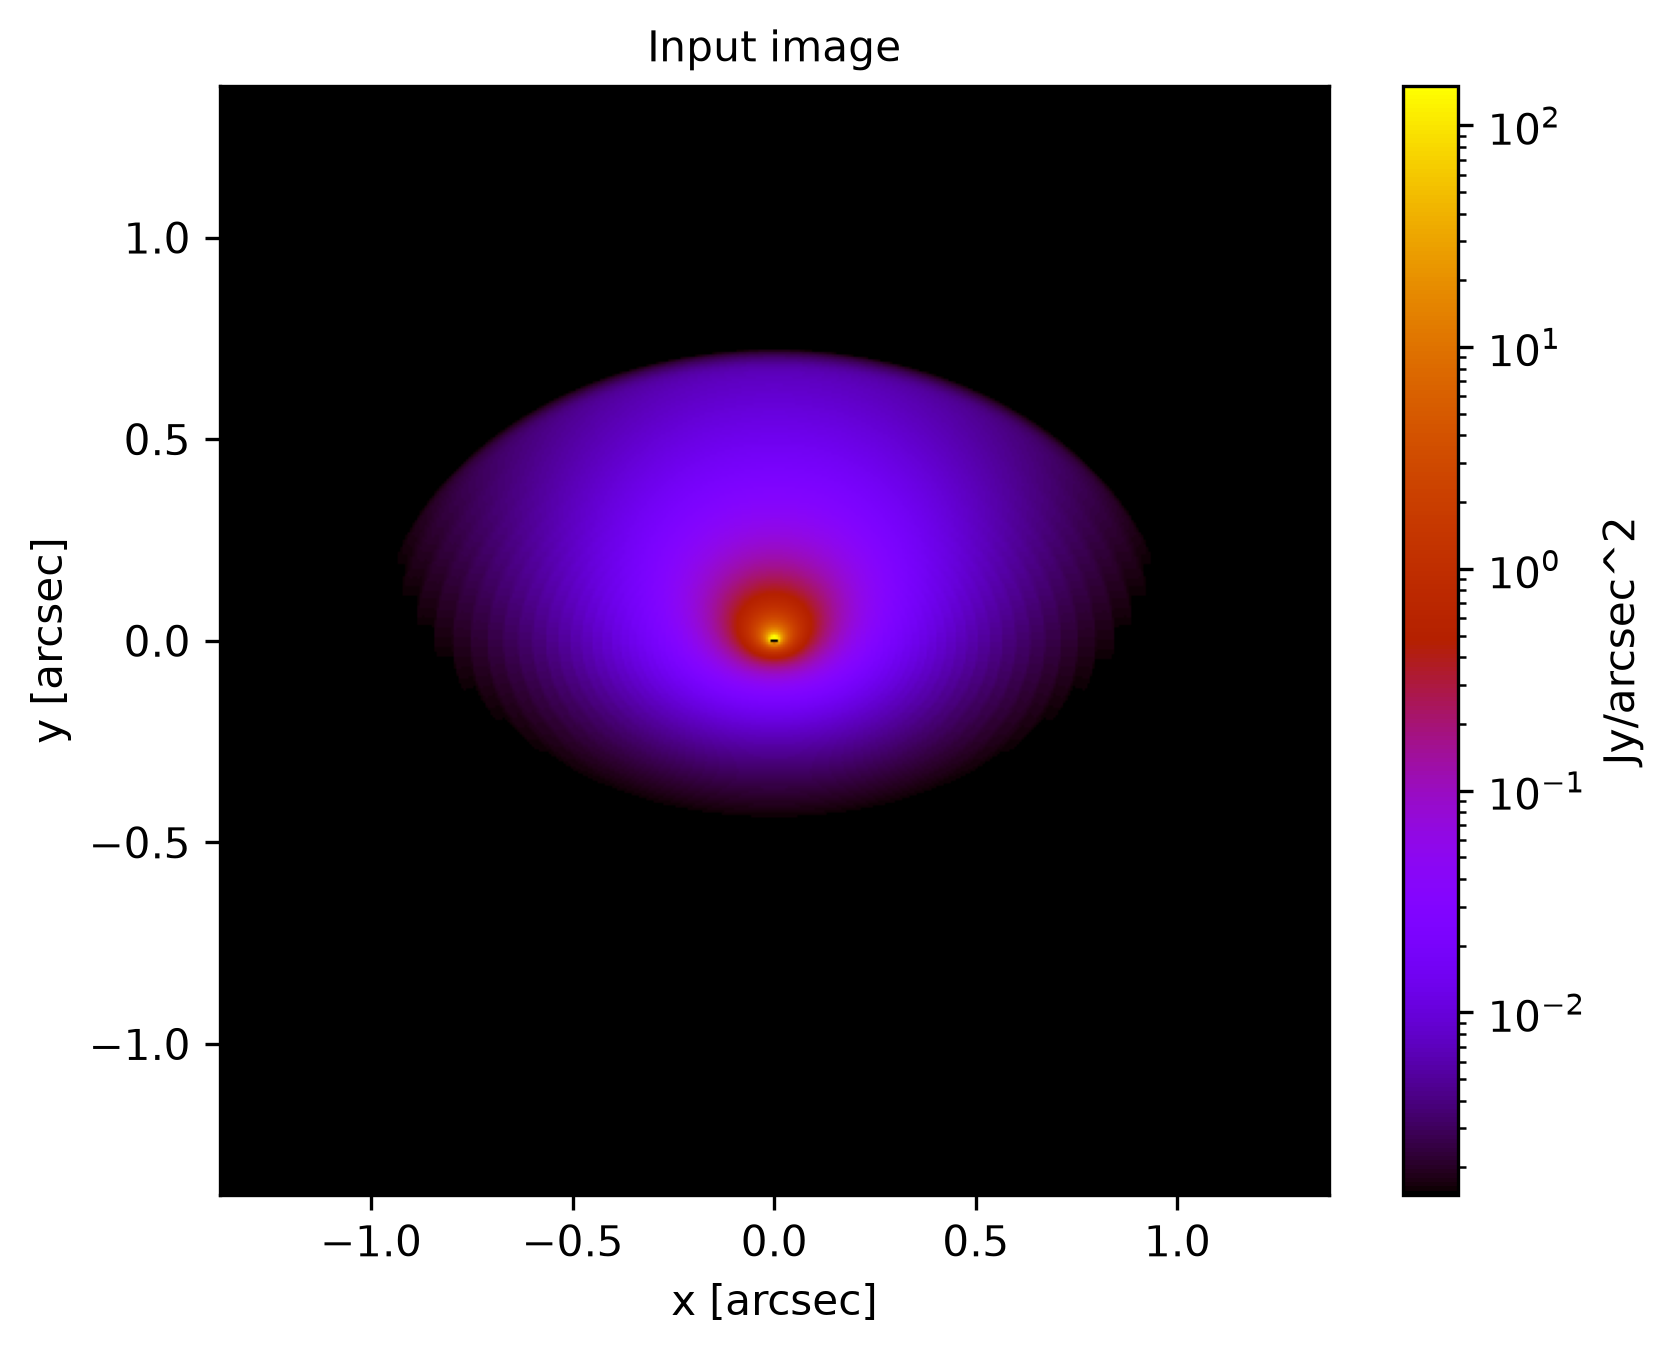

Kernel size K=131 (chosen for this image before: ./kernel_vortex_c6_N455_range27.8241_lyot0.95_a9d1f175389345dd.json)


Spatial PSF model K=131: from ./model_vortex_c6_N455_range27.8241_lyot0.95_rotate_K131_40883e23a820cef3.npz
Estimated error of this image (flux-weighted, from the PSF check): typical 1.7%, up to 3.2%; largest part: kernel crop (K=131) (1.7%)


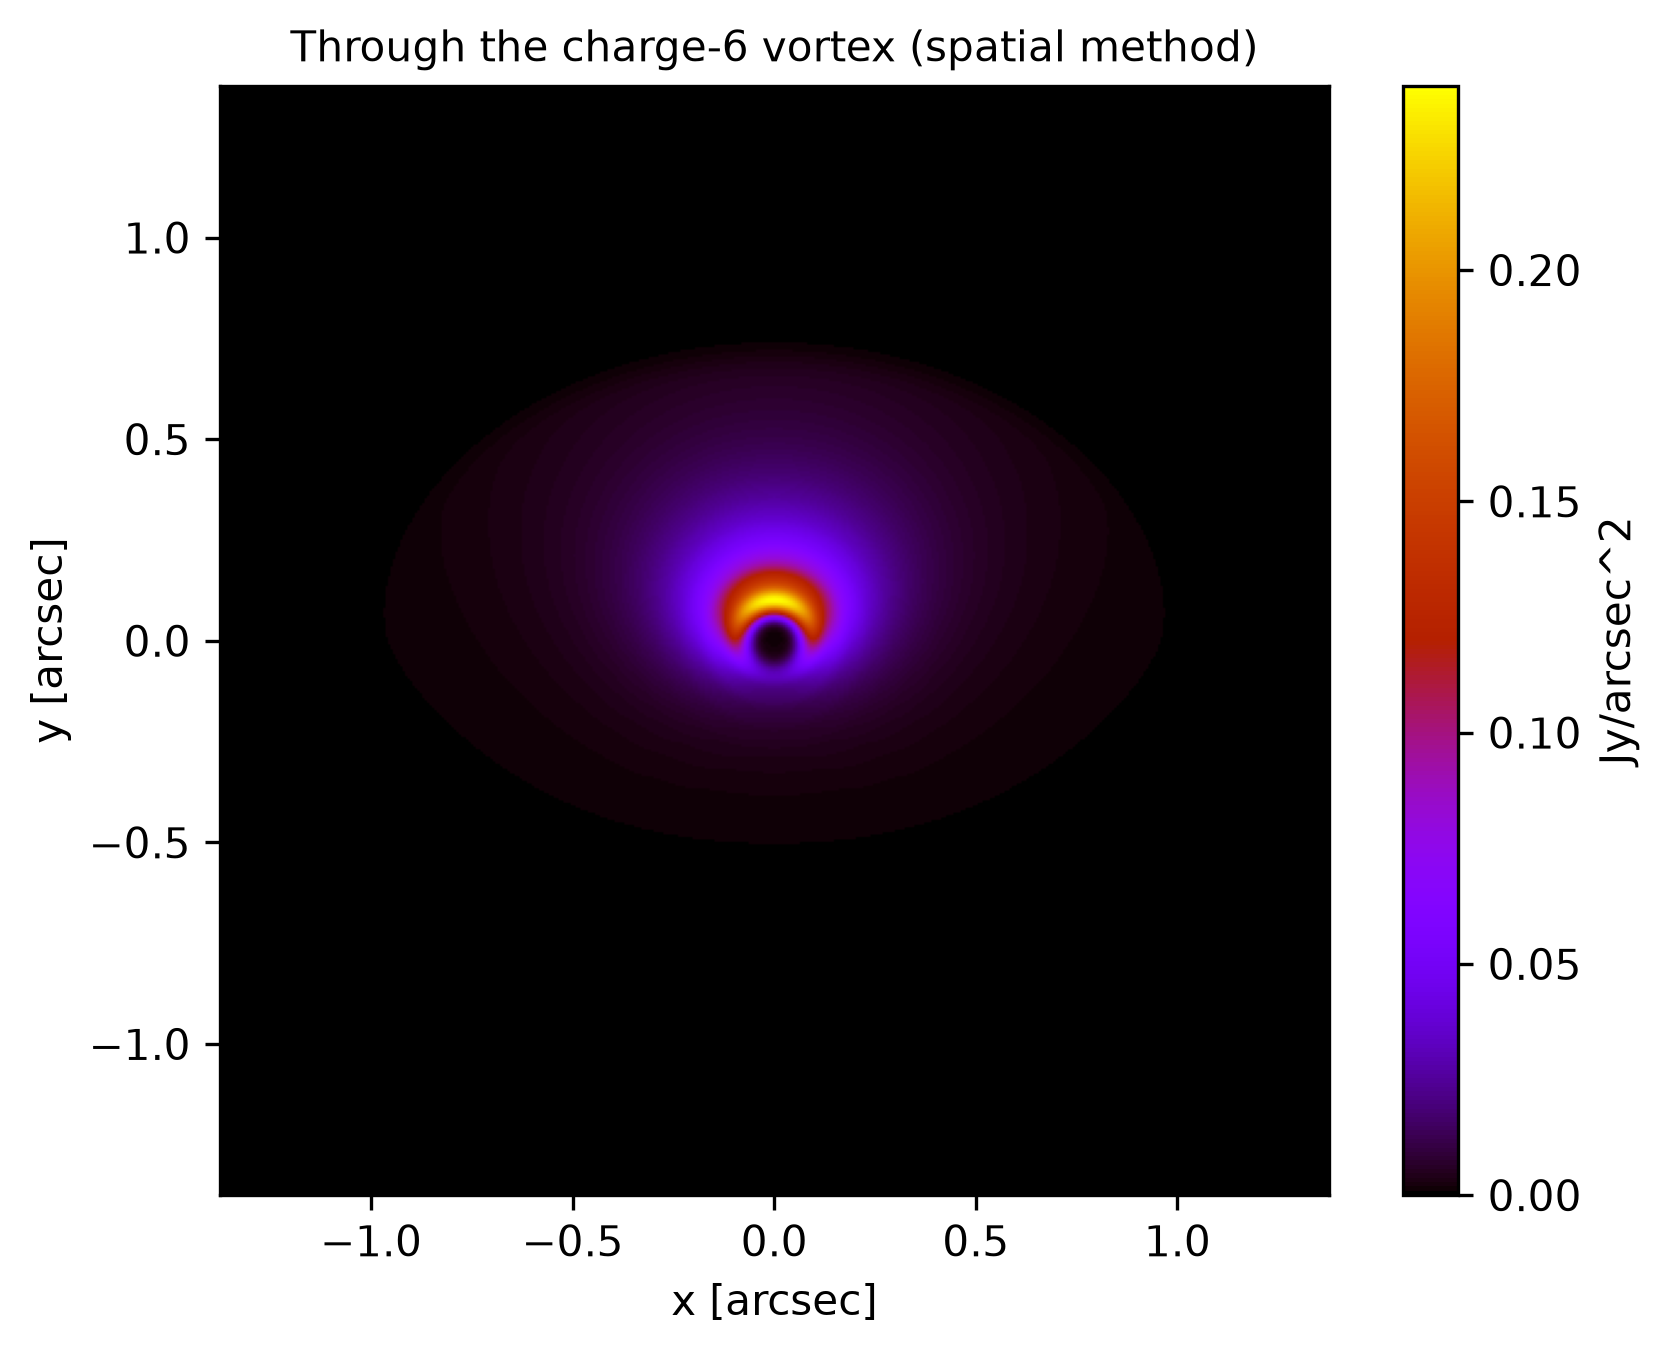

In [29]:
# Images of other targets start with the target's name: 45_575_origin.png and 45_575_charge6_spatial_final.png
disk.plot_origin(log=True)
final_image = disk.plot_final(charge=6)

## Your own target: any FITS image

Any image works:
* It must be a **square 2-D array**. For a cube, pick the plane with `slice`, e.g. `[0]` for the first plane of a 3-D cube.
* The **star must be at the centre of the array**: pixel (N-1)/2, counting from 0.
* The header keywords:
  * `BUNIT`: `W/m^2/pixel`, `Jy/arcsec^2` or `Jy/pixel`;
  * `PIXSCALE`: arcsec per pixel (or `CDELT1`/`CDELT2` in degrees);
  * `WAVELEN`: wavelength in m.

  Without them, set `input_unit` in the source table and `[observation] wavelength` / `[grid] fov` in the parameter file.

Here: a narrow ring inclined by 60°, at 0.8 µm with a 2.4 m telescope, and a tighter error target of 1%. The spatial method then picks a bigger kernel (K=117, typical error 0.9%).

Expected output:
```
Input: my_ring.fits (image), 256 x 256, Jy/arcsec^2; 0.01 arcsec/pixel (header PIXSCALE of my_ring.fits) = 37.23 lambda/D across at 8e-07 m (header WAVELEN of my_ring.fits)
Method: spatial, rotate mode (auto; target not symmetric: asymmetry 94%, ...)
Kernel size K=117 (+-8.4 lambda/D): estimated crop error 0.77% of the image light (80% of the 1% error target; 48 probe pixels)
...
Estimated error of this image (flux-weighted, from the PSF check): typical 0.89%, up to 0.94%; largest part: kernel crop (K=117) (0.79%)
```

Input: my_ring.fits (image), 256 x 256, Jy/arcsec^2; 0.01 arcsec/pixel (header PIXSCALE of my_ring.fits) = 37.23 lambda/D across at 8e-07 m (header WAVELEN of my_ring.fits)


Method: spatial, rotate mode (auto; target not symmetric: asymmetry 94%, light in the corners 0% (tol 1%); PSFs symmetric: vortex model)
Kernel size K=117 (chosen for this image before: ./kernel_vortex_c2_N256_range18.6168_lyot0.95_e45e3e0f4ba83b91.json)
Spatial PSF model K=117: from ./model_vortex_c2_N256_range18.6168_lyot0.95_rotate_K117_c3859290e33a8208.npz
Estimated error of this image (flux-weighted, from the PSF check): typical 0.89%, up to 0.94%; largest part: kernel crop (K=117) (0.79%)


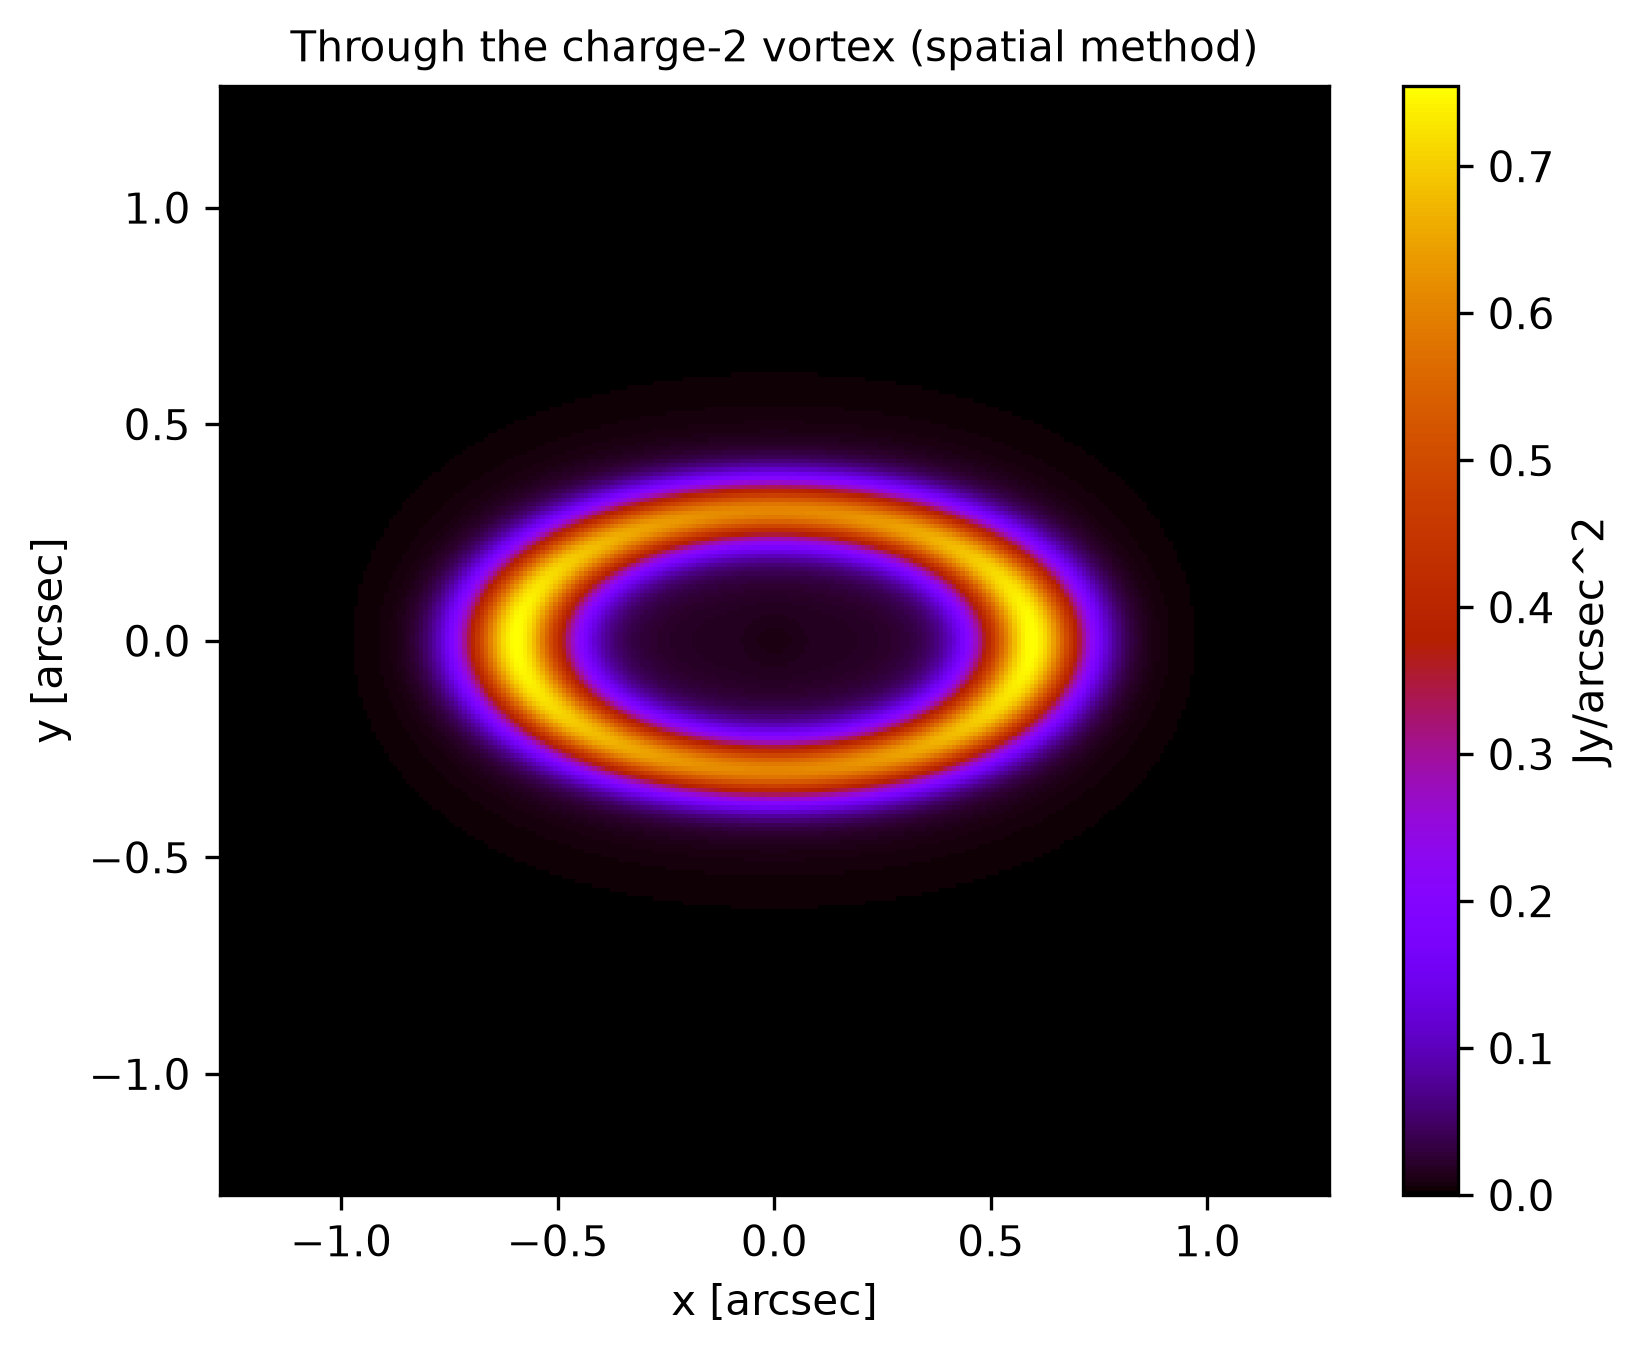

In [30]:
# Any image works: a square 2-D array with the star at its centre, and the header keywords BUNIT
# (W/m^2/pixel, Jy/arcsec^2 or Jy/pixel), PIXSCALE (arcsec per pixel) and WAVELEN (m) - or set
# input_unit / wavelength / fov in the parameter file instead. Here: an inclined ring.
import numpy as np
from astropy.io import fits
n = 256
y, x = np.indices((n, n))-(n-1)/2
ring = np.exp(-0.5*((np.hypot(x, y/np.cos(np.radians(60)))-60)/8)**2)  # a ring inclined by 60 degrees
header = fits.Header([("BUNIT", "Jy/arcsec^2"), ("PIXSCALE", 0.01), ("WAVELEN", 0.8e-6)])
fits.PrimaryHDU(ring, header).writeto("my_ring.fits", overwrite=True)
with open("my_ring.toml", "w") as f:
    f.write('[observation]\ndiameter = 2.4\n[[source]]\nkind = "fits_image"\nfile = "my_ring"\n[method]\nerror_target = 0.01\n')
my_target = toy.Target(para_file="my_ring.toml")
method, spatial_mode = my_target.check_symmetry()
final_image = my_target.plot_final(charge=2)  # saved to my_ring_charge2_spatial_final.png

## Scenes: a real system built from modules

So far one image went through one coronagraph. A **scene** puts any number of inputs (modules) on one grid, and `observe()` sends them through any number of coronagraphs. Here: **epsilon Eridani**, observed at 632 nm with Lazuli's 3.0 m aperture over the 3.0″ field of its WCC detector: first its exozodiacal dust alone through two sets of PSFs, then the whole system.

**The star itself is not simulated**: neither its image nor its light leaking through the coronagraph. Brightnesses are given as fractions of the star's light ("contrast") only as a unit.

**Pixel sampling.** The WCC detector's own pixels (0.0184″) give only 2.36 pixels per lambda/D at 632 nm. The vortex model (hcipy) samples its pupil from the image's pixels, so at that sampling its PSFs' far wings come out 5% too low near the image edge (10% in the corners), while at 5 pixels per lambda/D they are right to about 1%. So the scenes below use `sampling=5, fov=3.0` (`[grid] sampling = 5` and `fov = 3.0` in a parameter file): 345 pixels of 0.0087″, an odd size as Lazuli's PSFs require. Below 5 pixels per lambda/D the vortex gives a `SamplingWarning` that says so. Lazuli's PSFs have their own pupil sampling (512 samples, enough for this field: they need about 13 samples per lambda/D of the image's half-width; below that they warn too), so they are right at any pixel size.

**Your own module** (here `Exozodi`) is a class that declares its parameters (`Param`: name, default, unit, description) and draws its image in `render(grid, star)`; `tests/extra_sources.py` is a longer template. In a parameter file it is used with `kind = "exozodi"` and `module = "<the Python module defining it>"`.

In [31]:
import numpy as np
from toycoronagraph.params import Param, ParamError
from toycoronagraph.sources import Source, register_source
from toycoronagraph.units import SourceImage
from toycoronagraph.scene import Scene, Star, write_scene
from toycoronagraph.sources.thomson import Wind
from toycoronagraph.sources.cme import Cme
from toycoronagraph.sources.planets import Planet
from toycoronagraph.sources.images import SceneFits, FitsImage
from toycoronagraph.observe import observe, video, Result


# Your own module: a class declaring its parameters and drawing its image (template: tests/extra_sources.py)
@register_source
class Exozodi(Source):
    """A face-on exozodiacal dust disk: surface brightness ~ r^-alpha between r_in and r_out, holding
    `total` of the star's light within the image (contrast, so no stellar spectrum is needed)."""
    kind = "exozodi"
    doc = "a face-on exozodiacal dust disk"
    family = "relative"                      # a fraction of the star's light
    requires = ("star.distance",)            # au <-> arcsec
    params = (
        Param("total", 2e-7, doc="the disk's light in the image / the star's light", min=0),
        Param("r_in", 0.1, unit="AU", doc="inner edge", min=0),
        Param("r_out", 10.0, unit="AU", doc="outer edge (10 au: beyond the image, so no edge shows)", min=0),
        Param("alpha", 2.34, doc="surface brightness ~ r^-alpha (zodiacal dust: 2.34)", min=0),
    )

    def render(self, grid, star):
        """The disk's contrast per pixel on the scene grid (SourceImage, contrast_pixel)."""
        s = self.settings
        x, y = grid.coordinates()                      # arcsec from the star
        r = np.hypot(x, y)*star.distance                # au (1 arcsec at d pc = d au)
        inside = (r >= s["r_in"]) & (r <= s["r_out"])
        brightness = np.where(inside, np.maximum(r, 1e-9)**-s["alpha"], 0.0)
        return SourceImage(s["total"]*brightness/brightness.sum(), "contrast_pixel", origin="exozodi")

    def symmetric(self):
        """Face-on: circularly symmetric."""
        return True

### First, the exozodi alone, through two sets of PSFs

**The system** is epsilon Eridani, a K2V star **3.22 pc** away: 1 arcsec there is 3.22 au. With Lazuli's 3.0 m aperture at 632 nm, lambda/D is 0.043 arcsec, or 0.14 au. The scenes below set the distance once, in `Star(distance=3.22)` (`[star] distance` in a parameter file); the wind, the CME and the dust use it to place their light in au, and plots with `axis="au"` use it to label distances.

One input and two coronagraphs, to see what the choice of PSFs does before other inputs come in. The exozodi (2e-7 of the star's light, about 10 zodis, from 0.1 au out past the field's edge, which is 4.8 au away and 6.8 au in the corners) is circularly symmetric, so it goes through the exact circular method: any difference between the two final images comes from the PSFs.

The two sets here are two independent models of the same optics, both with a charge-6 vortex and a 0.95 Lyot stop:
* `"vortex:6"`: the ideal vortex of **hcipy** on the scene's 3.0 m circular aperture;
* `{"type": "lazuli", "charge": 6}`: **Lazuli's** PSFs, computed with prysm.

`plot_compare(first, second)` shows
1. both final images, on one colour scale;
2. their relative difference, (second − first) / first, where the first is within 5 decades of its peak (grey elsewhere); the title gives its median and the value that 99% of the pixels stay within;
3. the azimuthal means of the input and of both final images.

Any other pair of coronagraphs is compared the same way, e.g. `"vortex:2"` and `"vortex:6"` (two charges), or `{"type": "lazuli", "charge": 0}` and `{"type": "lazuli", "charge": 6}` (the telescope alone and with a vortex).

Note: [star] radius is not used by any enabled component: you can remove it
Scene: 345 x 345 px, 0.0086906 arcsec/pixel (5 px per lambda/D at 6.32e-07 m); exozodi; in contrast_pixel


vortex_c6, exozodi: Method: circular (auto; target symmetric: known by the exozodi module; PSFs symmetric: vortex model)


lazuli_c6, exozodi: Method: circular (auto; target symmetric: known by the exozodi module; PSFs symmetric: lazuli model)


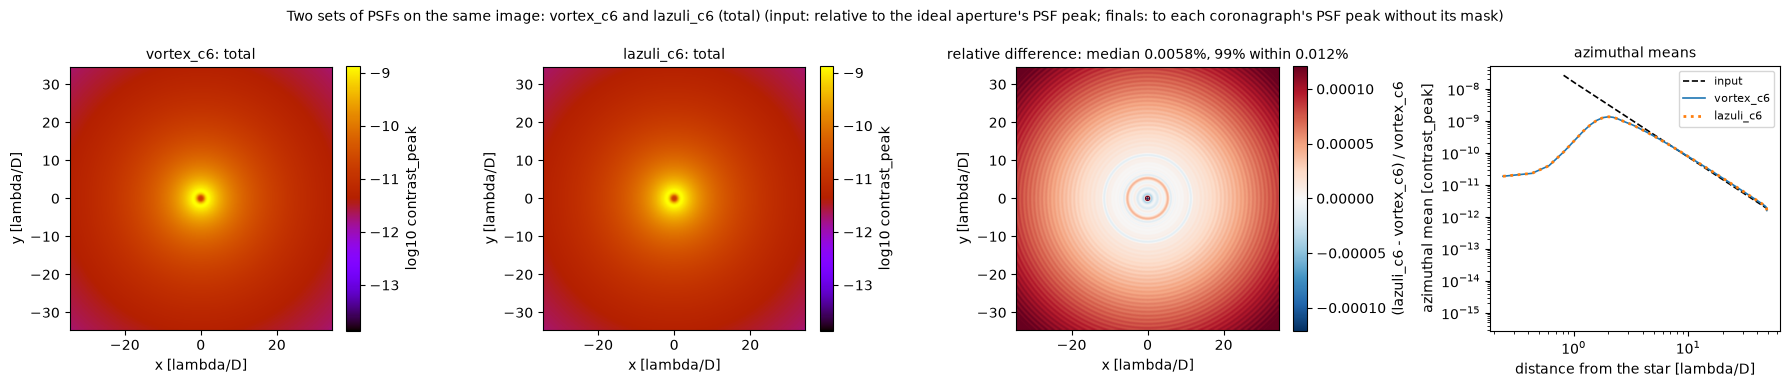

In [32]:
# The exozodi alone, through two sets of PSFs: hcipy's ideal vortex and Lazuli's (prysm), both charge 6
eps_eri = Star(distance=3.22, radius=0.73)                     # pc, R_sun (temperature=5080 K: for outputs in Jy)
dust = Scene(star=eps_eri, wavelength=632e-9, diameter=3.0,    # m: Lazuli's design wavelength and aperture
             sampling=5, fov=3.0)                              # 5 px per lambda/D over the WCC's 3.0" field: 345 px
dust.add(Exozodi(total=2e-7))                                  # ~10 zodis
dust_result = observe(dust, ["vortex:6", {"type": "lazuli", "charge": 6}])
fig = dust_result.plot_compare("vortex_c6", "lazuli_c6", unit="contrast_peak", axis="lambda/D")

**Reading it.** Both remove the same light near the star (the profiles overlap: the dust inside about 2 lambda/D is gone, and the vortex dims it out to about 5 lambda/D), and the two final images agree to 0.01%: a median difference of 0.006%, 99% of the pixels within 0.012%. Here the dust covers the whole field, so every pixel is dominated by light close to its source. The two models differ more in faint light far from any source, the PSFs' far wings: at the detector's own sampling (2.36 pixels per lambda/D) hcipy's would come out up to 9% too low, because its vortex model takes its pupil sampling from the image's pixels, while Lazuli's follow the exact Airy pattern to 1% (see "Pixel sampling" above).

### The whole system

Now the other inputs. Every value is meant to be realistic:

| Input | Value | Why |
|---|---|---|
| star | K2V, 3.22 pc, 0.73 R☉ | epsilon Eri (Gaia; interferometric radius); its temperature (5080 K) or `flux_jy` would only be needed for outputs in Jy |
| `wind` | 6e-13 M☉/yr at 400 km/s | about 30 times the Sun's mass loss, measured from its astrosphere (Wood et al. 2002) |
| `cme` | 1e17 g | as heavy as the largest solar CMEs (typical ones: ~1e15 g); an active K dwarf may launch them |
| `exozodi` (your own module) | 2e-7 of the star's light | ~10 zodis: the Sun's zodiacal dust intercepts ~1e-7 of the Sun's light and scatters ~20% of it |
| `planet` (epsilon Eri b) | 3.5 au = 1.09″, contrast 3e-9 | a Jupiter in reflected light: albedo 0.5 × (R_J / 3.5 au)² × a phase factor ~0.3 |
| telescope | 3.0 m, 632 nm, a 3.0″ field at 5 pixels per lambda/D | Lazuli's beam on M1, its design wavelength and its WCC detector's field (config_um, config_um_wcc), with pixels finer than the detector's (see "Pixel sampling" above) |

**Changing the wind and the CME.** Each module's parameters are keywords of its class, e.g. `Wind(mdot=1e-12, v=600)` or `Cme(mass=1e18, horizontal_height_factor=1.5)`, in the cell below. In a parameter file they are the keys of the module's `[[source]]` table (`kind = "wind"` or `kind = "cme"`; the section "Save, load, and scene files" below writes one). Both modules need `[star] distance`; the CME also needs the star's `radius`, and the wind starts at `r_in` stellar radii.

**`wind`**: starlight scattered by the electrons of a stellar wind (`toycoronagraph/sources/thomson.py`). Its brightness falls as r⁻³ from the star.

| Key | Default | Meaning |
|---|---|---|
| `mdot` | (required) | mass-loss rate, M☉/yr |
| `v` | 400 km/s | wind speed (constant unless `velocity_law = "beta"`) |
| `mu_e` | 1.0 | mass per electron, in atomic mass units (about 1.17 for solar gas) |
| `r_in` | 1.0 | where the wind starts, in stellar radii |
| `velocity_law` | `"constant"` | or `"beta"`: v0 + (v − v0)(1 − r_in/r)^beta, slower near the star (so denser and brighter there) |
| `beta` | 1.0 | exponent of the beta law |
| `v0` | 10 km/s | speed at `r_in` (beta law) |
| `phase_function` | `"isotropic"` | or `"thomson"`: the (1 + cos²) angular dependence of Thomson scattering |

**`cme`**: starlight scattered by the electrons of a coronal mass ejection, the model of astro_toolbox's `cme_imaging` (`toycoronagraph/sources/cme.py`): a shell spanning ±45° around +x.

| Key | Default | Meaning |
|---|---|---|
| `mass` | 1e19 g | CME mass (its light scales with it) |
| `dR_factor` | 0.2 | shell thickness, as a fraction of the half box |
| `vertical_height_factor` | 1.0 | vertical stretch of the shell |
| `horizontal_height_factor` | 0.0 | outward shift of the shell, in shell thicknesses (the CME video below changes it) |
| `smear`, `smear_sig` | false, 3.0 | Gaussian smoothing, sigma in model pixels |
| `mu_e` | 1.0 | mass per electron, in atomic mass units |
| `extent`, `dim` | `"auto"` | the model box's width (au) and size (odd, pixels); `"auto"`: the scene's field and grid |
| `toolbox_path`, `cme_args` | | use a newer `cme_imaging` from your astro_toolbox folder, with `make_cme()` arguments |

The full list of any module's keys, with their help text: `python -m toycoronagraph describe wind` (or `cme`, or any other module) in a terminal; in VS Code, hovering a key of a parameter file shows the same.

**The inputs**, one panel per component (log scale, 5 decades below each panel's peak; axes in au), and the total, where the planet (a point source, no image) is marked. The wind is brightest at the star and falls as r⁻³; the exozodi fills the field; the CME is a shell on one side.

Expected output:
```
wind     4.66e-07
cme      9.23e-12
exozodi  2.00e-07
```

Scene: 345 x 345 px, 0.0086906 arcsec/pixel (5 px per lambda/D at 6.32e-07 m); wind, cme, exozodi, eps_eri_b; in contrast_pixel


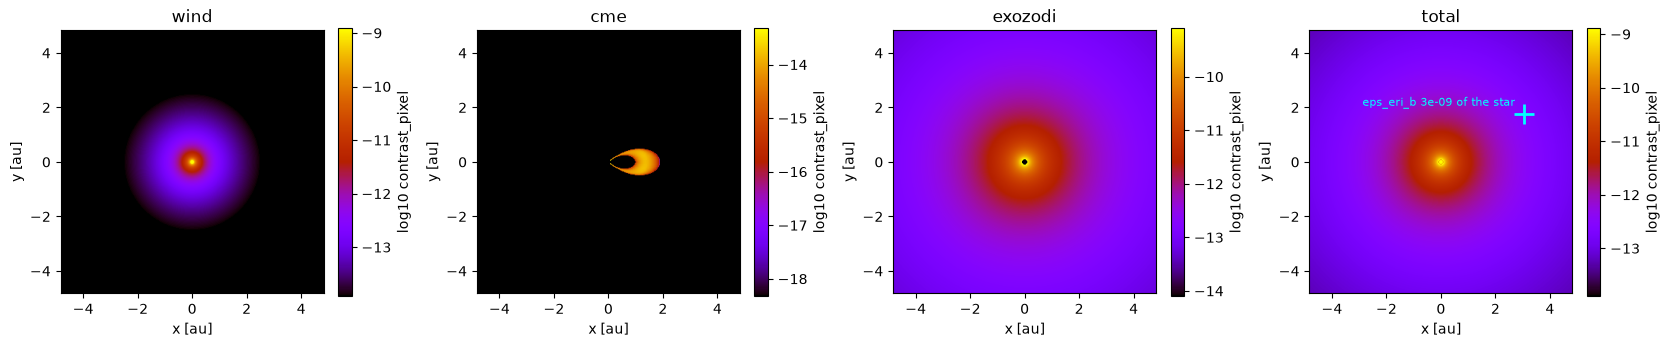

wind     4.66e-07
cme      9.23e-12
exozodi  2.00e-07


In [33]:
# epsilon Eridani at 632 nm through Lazuli's 3.0 m aperture: the wind, a CME, the exozodi and the planet
scene = Scene(star=eps_eri, wavelength=632e-9, diameter=3.0,   # m: Lazuli's design wavelength and aperture
              sampling=5, fov=3.0)                              # 5 px per lambda/D over the WCC's 3.0" field: 345 px
scene.add(Wind(mdot=6e-13, v=400))                               # M_sun/yr (30x the Sun's), km/s
scene.add(Cme(mass=1e17))                                        # g: as heavy as the largest solar CMEs
scene.add(Exozodi(total=2e-7))                                   # ~10 zodis
scene.add(Planet(mode="polar", pos=[1.09, 30], brightness=3e-9, brightness_unit="contrast"),
          name="eps_eri_b")                                      # 3.5 au; reflected light
images = scene.render()
fig = scene.plot(log=True, unit="contrast_pixel", axis="au")
for name, image in images.items():                                # each input's light / the star's
    print("%-8s %.2e" % (name, scene.in_unit(image, "contrast_pixel").sum()))

The wind holds 4.7e-7 of the star's light, most of it in the star's own pixel; the exozodi 2.0e-7; the CME only 9e-12 (spread over several au: far below anything detectable without the tricks of the CME section below); the planet 3e-9.

## PSF options: the coronagraphs

Each `[[coronagraph]]` table (or each entry of the list given to `observe`) is one optical system:

| `type` | What | Options |
|---|---|---|
| `"vortex"` (`"vortex:6"` for short) | an ideal vortex coronagraph (hcipy) on the scene's circular aperture | `charge` (even), `lyot_mask_size` (0.95) |
| `"lazuli"` | Lazuli's PSFs (prysm), from the UASAL configuration packages | `charge` (0: the telescope alone; even: an ideal vortex and a Lyot stop), `wavelengths` (`"auto"`: the observation's; a list for a band), `throughput` (`"auto"`: mirrors × r' filter × detector, per wavelength), `opd` (a wavefront error map; none: ideal optics), `pupil_samples`, `lyot_mask_size` |

How each component goes through is chosen per component (`[method] method = "auto"`): the **circular** method when the component and the PSFs are circularly symmetric (the wind and the exozodi here; exact and fast), the **spatial** method otherwise (the CME; kernel size from `error_target`, with an error estimate), and an **exact** PSF for every planet. `combine = "separate"` (the default) sends each component through on its own and keeps its final image; `"together"` sends their sum through once.

The first run computes and saves each coronagraph's PSFs (a few minutes for Lazuli with a vortex); later runs reuse them.

**The unit `contrast_peak`** is the usual coronagraph contrast: the surface brightness divided by the peak of the star's PSF through the same optics *without* the coronagraph's mask (the Lyot stop kept). Each coronagraph has its own peak (a 0.95 Lyot stop lowers it to 0.95⁴ = 0.81 of an ideal aperture's); the input row uses the ideal aperture's. A planet far from the star reads about its contrast times the coronagraph's throughput there.

The first figure puts every coronagraph's total final image side by side, on one colour scale (6 decades below the brightest panel), so they compare directly: the vortices remove the wind's bright centre and dim the dust near the star by 1-2 decades, while Lazuli without a coronagraph (`lazuli_alone`, `lazuli_band`) only blurs the input, the wind's centre becoming a bright PSF.

vortex_c2, wind: Method: circular (auto; target symmetric: known by the wind module; PSFs symmetric: vortex model)
Kernel size K=81 (chosen for this image before: ./kernel_vortex_c2_N345_range34.5_lyot0.95_85536468a2ba9488.json)
Spatial PSF model K=81: from ./model_vortex_c2_N345_range34.5_lyot0.95_rotate_K81_e81b22832286c376.npz
vortex_c2, cme: Method: spatial, rotate mode (auto; target not symmetric: asymmetry 1.6e+02%, light in the corners 0% (tol 1%); PSFs symmetric: vortex model); estimated error 1.5%


vortex_c2, exozodi: Method: circular (auto; target symmetric: known by the exozodi module; PSFs symmetric: vortex model)


vortex_c6, wind: Method: circular (auto; target symmetric: known by the wind module; PSFs symmetric: vortex model)
Kernel size K=79 (chosen for this image before: ./kernel_vortex_c6_N345_range34.5_lyot0.95_85536468a2ba9488.json)
Spatial PSF model K=79: from ./model_vortex_c6_N345_range34.5_lyot0.95_rotate_K79_11ef2382a5dded5a.npz
vortex_c6, cme: Method: spatial, rotate mode (auto; target not symmetric: asymmetry 1.6e+02%, light in the corners 0% (tol 1%); PSFs symmetric: vortex model); estimated error 1.6%
vortex_c6, exozodi: Method: circular (auto; target symmetric: known by the exozodi module; PSFs symmetric: vortex model)


lazuli_alone, wind: Method: circular (auto; target symmetric: known by the wind module; PSFs symmetric: lazuli model)
Kernel size K=85 (chosen for this image before: ./kernel_lazuli_N345_range34.5_8cd5d1a72ff6_85536468a2ba9488.json)
Spatial PSF model K=85: from ./model_lazuli_N345_range34.5_8cd5d1a72ff6_rotate_K85_0efab78f6a81e177.npz
lazuli_alone, cme: Method: spatial, rotate mode (auto; target not symmetric: asymmetry 1.6e+02%, light in the corners 0% (tol 1%); PSFs symmetric: lazuli model); estimated error 1.6%


lazuli_alone, exozodi: Method: circular (auto; target symmetric: known by the exozodi module; PSFs symmetric: lazuli model)


lazuli_c6, wind: Method: circular (auto; target symmetric: known by the wind module; PSFs symmetric: lazuli model)
Kernel size K=79 (chosen for this image before: ./kernel_lazuli_N345_range34.5_7ce3fca646a3_85536468a2ba9488.json)
Spatial PSF model K=79: from ./model_lazuli_N345_range34.5_7ce3fca646a3_rotate_K79_fc87de141c03fe0e.npz
lazuli_c6, cme: Method: spatial, rotate mode (auto; target not symmetric: asymmetry 1.6e+02%, light in the corners 0% (tol 1%); PSFs symmetric: lazuli model); estimated error 1.6%
lazuli_c6, exozodi: Method: circular (auto; target symmetric: known by the exozodi module; PSFs symmetric: lazuli model)


lazuli_band, wind: Method: circular (auto; target symmetric: known by the wind module; PSFs symmetric: lazuli model)
Kernel size K=85 (chosen for this image before: ./kernel_lazuli_N345_range34.5_ee290576ec78_85536468a2ba9488.json)
Spatial PSF model K=85: from ./model_lazuli_N345_range34.5_ee290576ec78_rotate_K85_5835230a1dd6f1c7.npz
lazuli_band, cme: Method: spatial, rotate mode (auto; target not symmetric: asymmetry 1.6e+02%, light in the corners 0% (tol 1%); PSFs symmetric: lazuli model); estimated error 1.6%


lazuli_band, exozodi: Method: circular (auto; target symmetric: known by the exozodi module; PSFs symmetric: lazuli model)


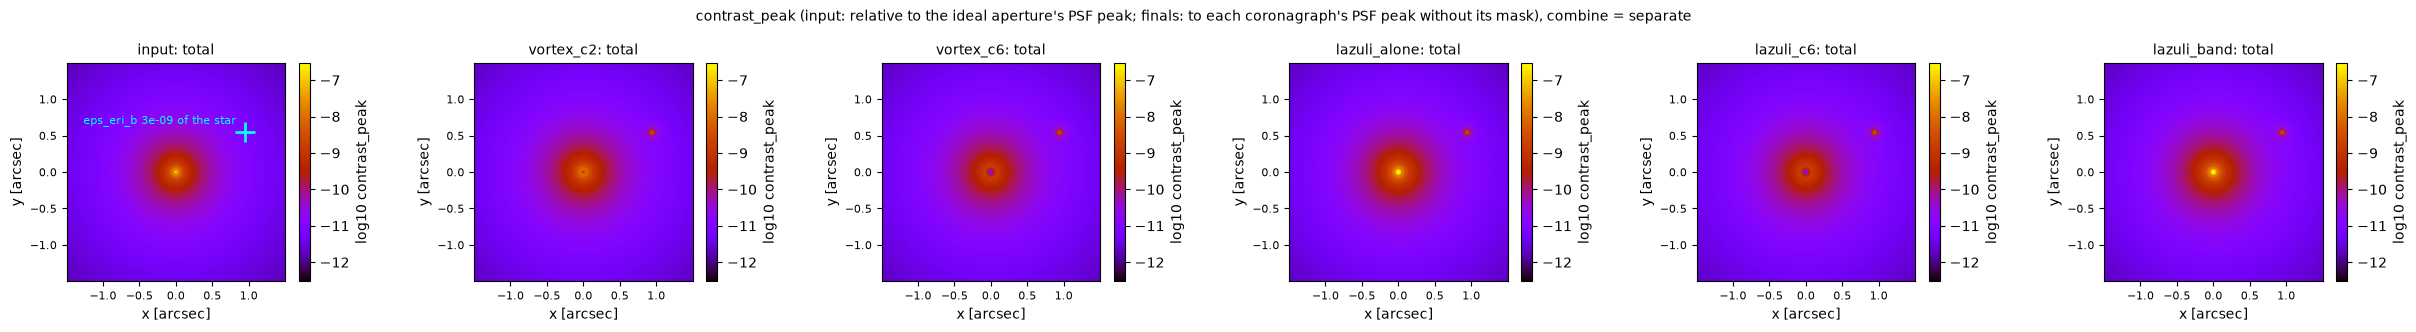

In [34]:
# vortex: an ideal vortex (hcipy) on the scene's aperture; lazuli: Lazuli's PSFs (prysm) - the telescope
# alone (no vortex: charge = 0), with an ideal vortex (charge 6), or alone over part of the r' band (weights
# from the mirrors, the filter and the detector). Without an OPD map the optics are ideal.
coronagraphs = ["vortex:2", "vortex:6",
                {"type": "lazuli", "charge": 0, "name": "lazuli_alone"},
                {"type": "lazuli", "charge": 6},
                {"type": "lazuli", "charge": 0, "wavelengths": ["600 nm", "632 nm", "665 nm"], "name": "lazuli_band"}]
result = observe(scene, coronagraphs)   # combine = "separate": each component through each coronagraph
fig = result.plot(unit="contrast_peak", components=["total"], log_range=6)   # the totals, side by side

**Each component through one coronagraph**: `coronagraphs=` and `components=` pick the rows and the columns (`input=False` drops the input row); each column has one colour scale (`shared=False`: one per panel). Here the charge-6 vortex of hcipy and Lazuli's: the two codes give the same images. Through the coronagraph the wind keeps only a faint halo, the CME keeps its shape (most of its light is far from the star), and the planet becomes an Airy pattern at its position. The CME's square edge, 4 decades below its peak, is the spatial method's kernel (39 x 39 pixels): the light it leaves out is within the error target (2%).

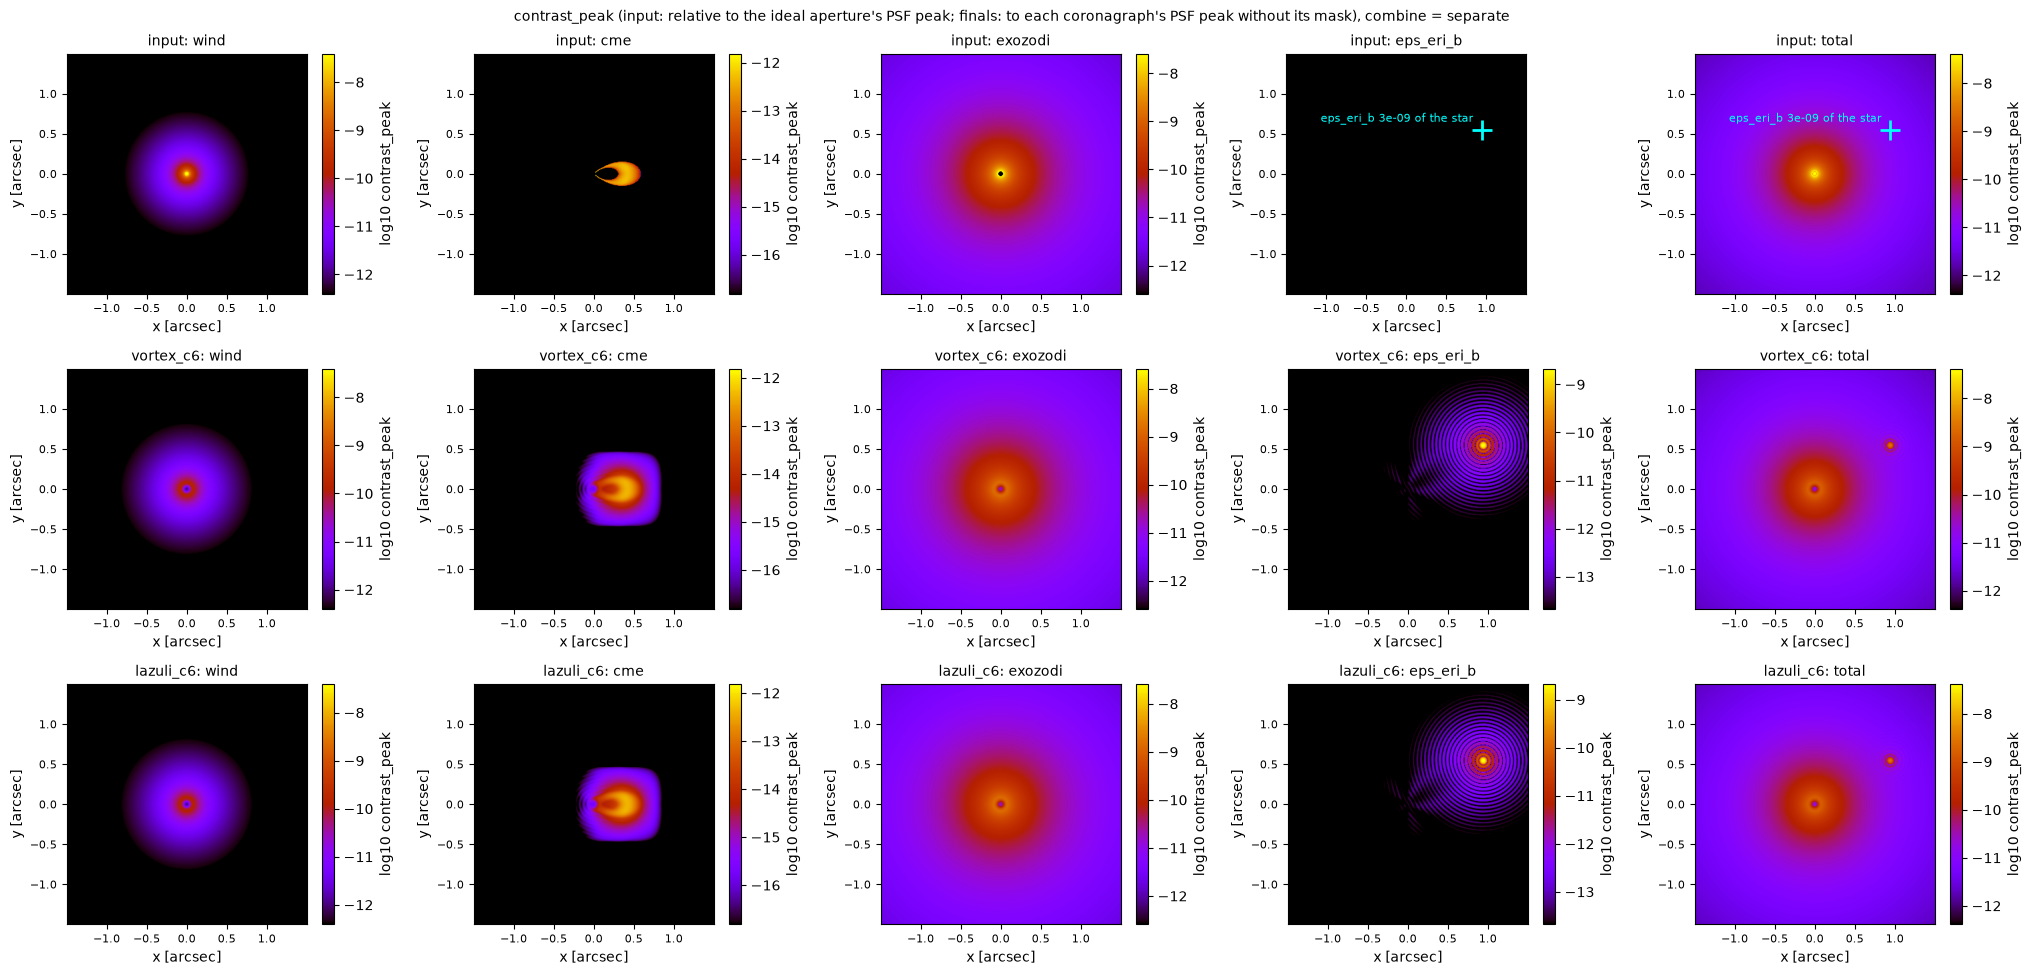

In [35]:
# The input and two coronagraphs, one column per component
fig = result.plot(unit="contrast_peak", coronagraphs=["vortex_c6", "lazuli_c6"])

**An OPD map** (optical path difference: the wavefront error across the pupil, in nm) adds the optics' aberrations: it lowers the PSF's peak (the Strehl ratio) and spreads light into a halo of speckles. Without one the optics are ideal. Lazuli's measured mirror maps are not bundled, so this one is illustrative: 20 nm RMS of astigmatism and coma. An OPD makes the PSFs not circularly symmetric, so whole images would go through the spatial method (slower); here only the planet is sent through (`components=[...]`), whose PSF is computed exactly. **Expected**: a Strehl ratio of about 0.96 (Maréchal: exp(-(2π · 20/632)²) = 0.96).

Expected output:
```
Strehl ratio of the planet's image: 0.961
```

In [36]:
# An illustrative OPD map: 20 nm RMS of astigmatism and coma, in nm, on 512 x 512 pupil samples (enough for this
# field; a coarser map would set fewer pupil samples, and a SamplingWarning would say so)
n = 512
v, u = (np.indices((n, n))-(n-1)/2)/(n/2)                         # pupil coordinates, -1..1
rho, phi = np.hypot(u, v), np.arctan2(v, u)
opd = np.where(rho <= 1, rho**2*np.cos(2*phi) + (3*rho**3-2*rho)*np.sin(phi), 0.0)
opd *= 20/opd[rho <= 1].std()
fits.PrimaryHDU(opd, fits.Header([("BUNIT", "nm")])).writeto("lazuli_example_opd.fits", overwrite=True)
aberrated = observe(scene, [{"type": "lazuli", "charge": 0, "opd": "lazuli_example_opd.fits", "name": "lazuli_opd"}],
                    components=["eps_eri_b"])                    # the planet only: its PSF is computed exactly
ideal = result.final("lazuli_alone", "eps_eri_b")
print("Strehl ratio of the planet's image: %.3f" % (aberrated.final("lazuli_opd", "eps_eri_b").max()/ideal.max()))

Strehl ratio of the planet's image: 0.961


## How much of the final image is each input?

The same inputs end up in very different proportions after a coronagraph. `plot_contributions` shows it pixel by pixel. **How to read it**: one row per image (the input, then each coronagraph); in each row, a component's panel is its fraction of that row's image at each pixel (yellow: it is all of the light there; dark: none), and its title gives its share of the row's whole light. The last panel colours each pixel by the component that dominates it.

* **The wind** is 70% of the input light, but most of it lies in the star's own pixel, which a vortex removes like the star: its share falls to 10% (charge 2) and 4% (charge 6).
* **The exozodi** then dominates the final image (88-93%) everywhere but the planet's core: it fills the field, out past the planet's orbit. A higher charge removes more of it too (much of its light is close to the star), but it dims the planet less than the dust: the planet's share grows from 1.6% (charge 2) to 2.7% (charge 6).
* **The planet** dominates its own core and its first Airy rings, in every row after a coronagraph.
* **Without a coronagraph** (`lazuli_alone`, `lazuli_band`) every input keeps its light (the shares stay those of the input); the wind's bright centre spreads its diffraction rings over the image (the rings in its share), but it dominates only at the star.
* The CME (1e-11 of the star's light) dominates nowhere.

The numbers below compare the planet with everything else inside its core (its final image above half its peak). They are the same for every coronagraph: at 3.5 au, far outside every IWA, what lies under the planet is the exozodi there, and every coronagraph passes the planet and that dust alike. So the dust at the planet's own distance, not the light near the star, sets the planet's background here. The star itself is not simulated: its own light, leaking through the coronagraph or, without one, its whole image, would add to it.

Expected output:
```
vortex_c2    planet / rest of the light in its core: 2.1e+02
vortex_c6    planet / rest of the light in its core: 2.1e+02
lazuli_alone planet / rest of the light in its core: 2.1e+02
lazuli_c6    planet / rest of the light in its core: 2.1e+02
lazuli_band  planet / rest of the light in its core: 2.1e+02
```

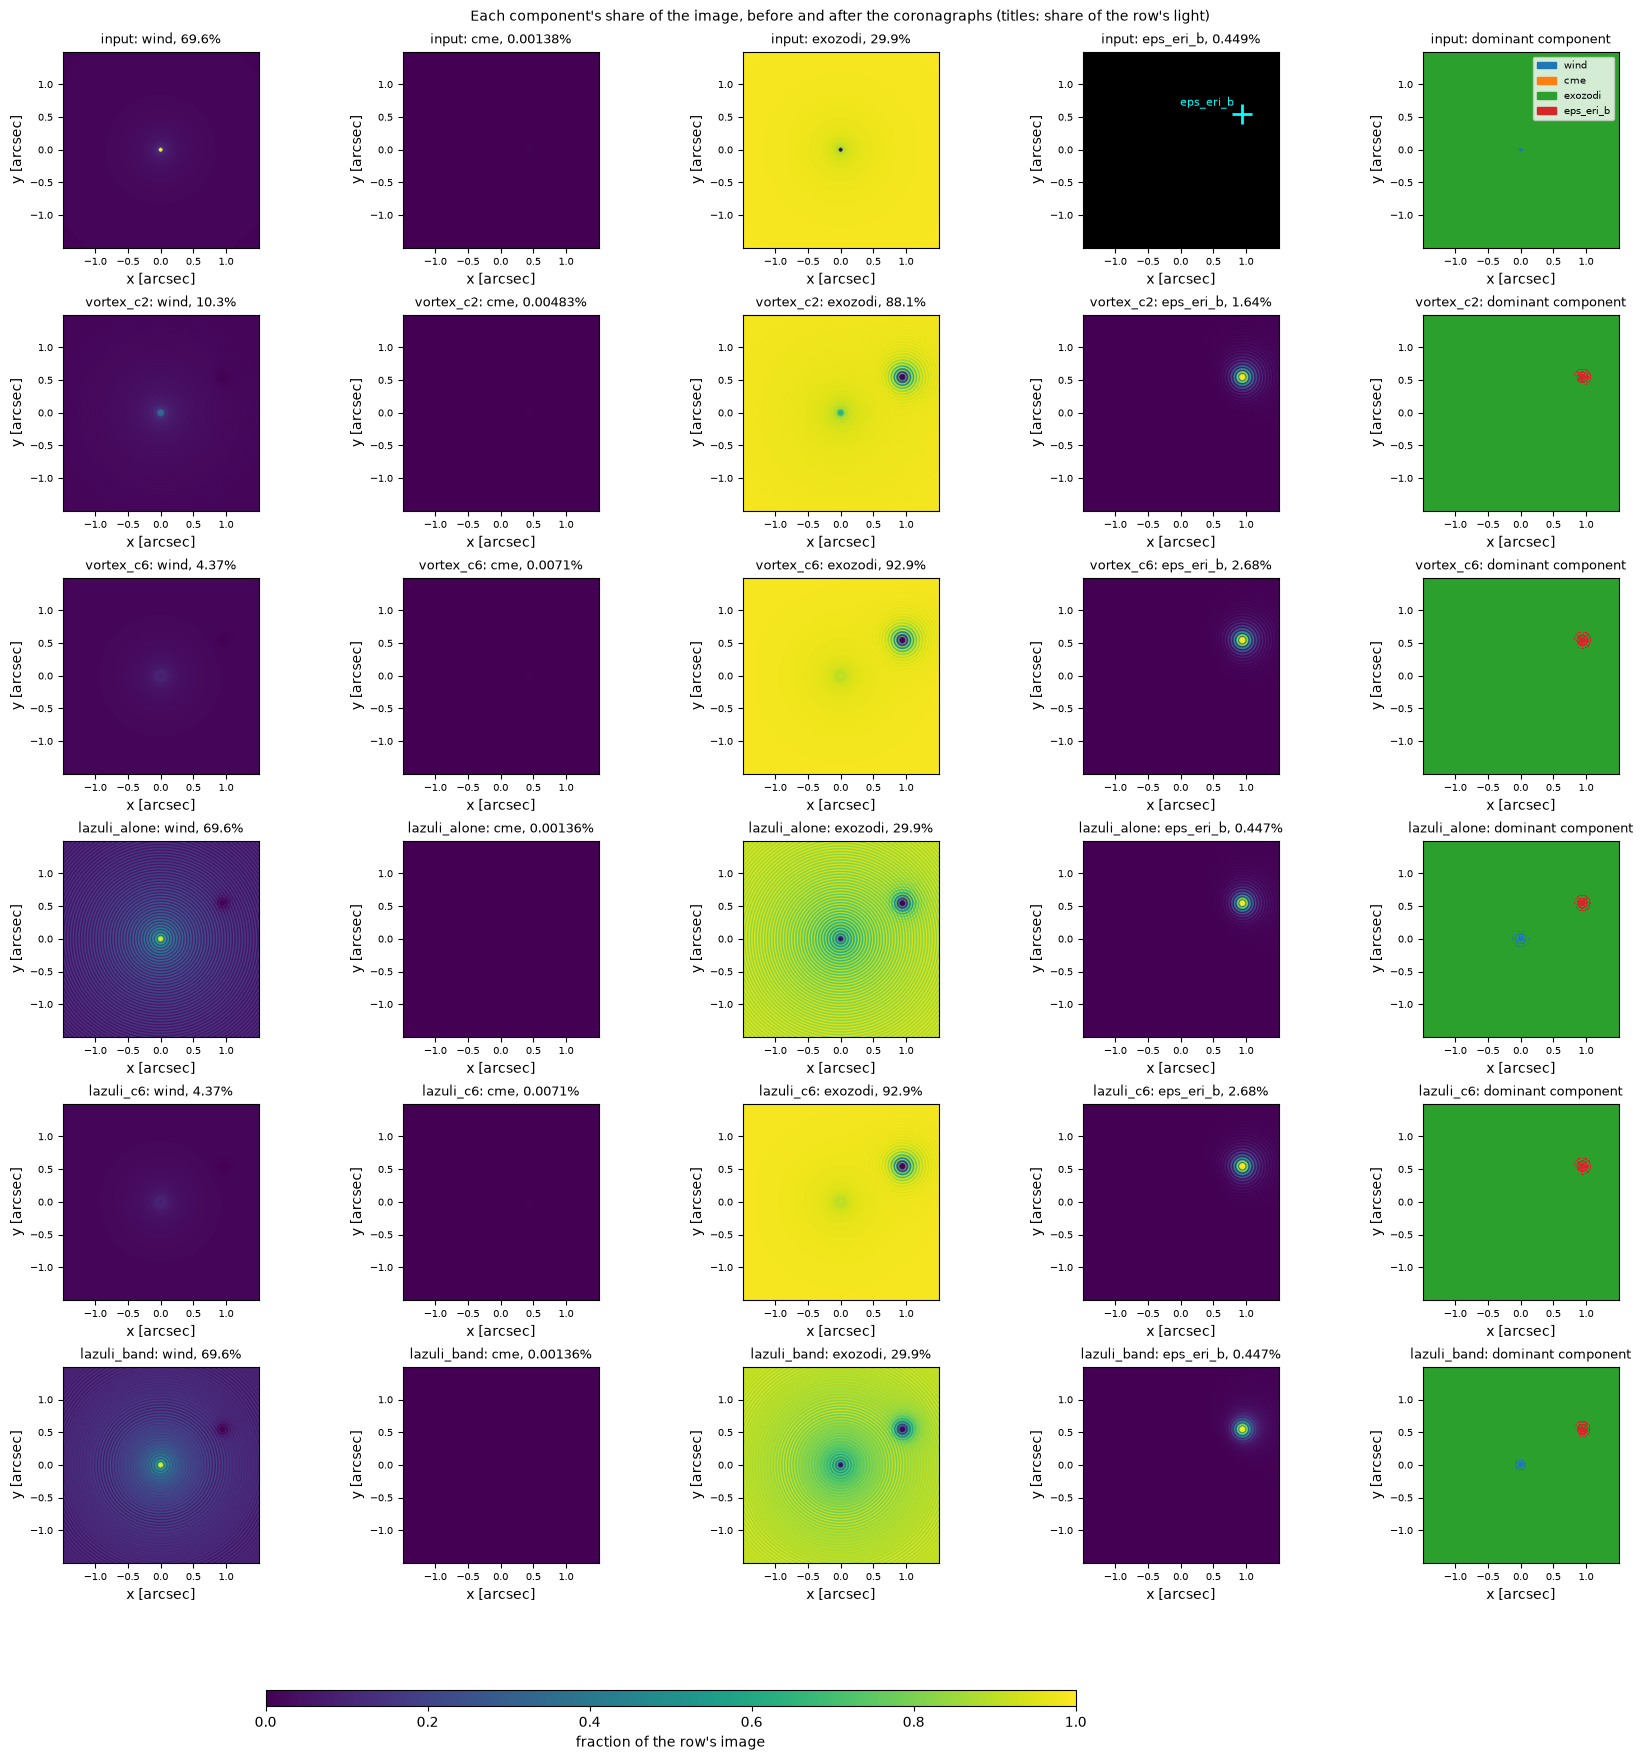

vortex_c2    planet / rest of the light in its core: 2.1e+02
vortex_c6    planet / rest of the light in its core: 2.1e+02
lazuli_alone planet / rest of the light in its core: 2.1e+02
lazuli_c6    planet / rest of the light in its core: 2.1e+02
lazuli_band  planet / rest of the light in its core: 2.1e+02


In [37]:
# Each component's share of the image, pixel by pixel: the input and every coronagraph
fig = result.plot_contributions(axis="arcsec")

# Inside the planet's core (its final image above half its peak): the planet against everything else
for coronagraph in result.finals:
    core = result.contrast("eps_eri_b", coronagraph)
    print("%-12s planet / rest of the light in its core: %.2g" % (coronagraph, core["eps_eri_b"]/(sum(core.values())-core["eps_eri_b"])))

**Radial profiles**: the azimuthal mean of each component before (dashed) and after (solid) each coronagraph, against the distance from the star in au (`axis="au"`, from the star's 3.22 pc; `"lambda/D"`, `"arcsec"` and `"pixel"` work too), one panel per coronagraph (the grey line is the total). The dotted line marks each coronagraph's **inner working angle** (IWA): the distance at which a point source's light through the coronagraph is half of what it is far from the star (`result.iwa(name)`, in arcsec). Charge 2 has it at 0.86 lambda/D (0.12 au), charge 6 at 2.4 lambda/D (0.33 au); the telescope alone (`lazuli_alone`, `lazuli_band`) has none. The vortices remove the light inside about 0.3 au (charge 2) and 0.6 au (charge 6) and leave the rest as it was; without a coronagraph the wind's diffraction rings lift its profile far above its input. The planet is the peak at 3.5 au.

Expected output:
```
vortex_c2    IWA: 0.038 arcsec = 0.12 au
vortex_c6    IWA: 0.103 arcsec = 0.33 au
lazuli_alone IWA: none
lazuli_c6    IWA: 0.103 arcsec = 0.33 au
lazuli_band  IWA: none
```

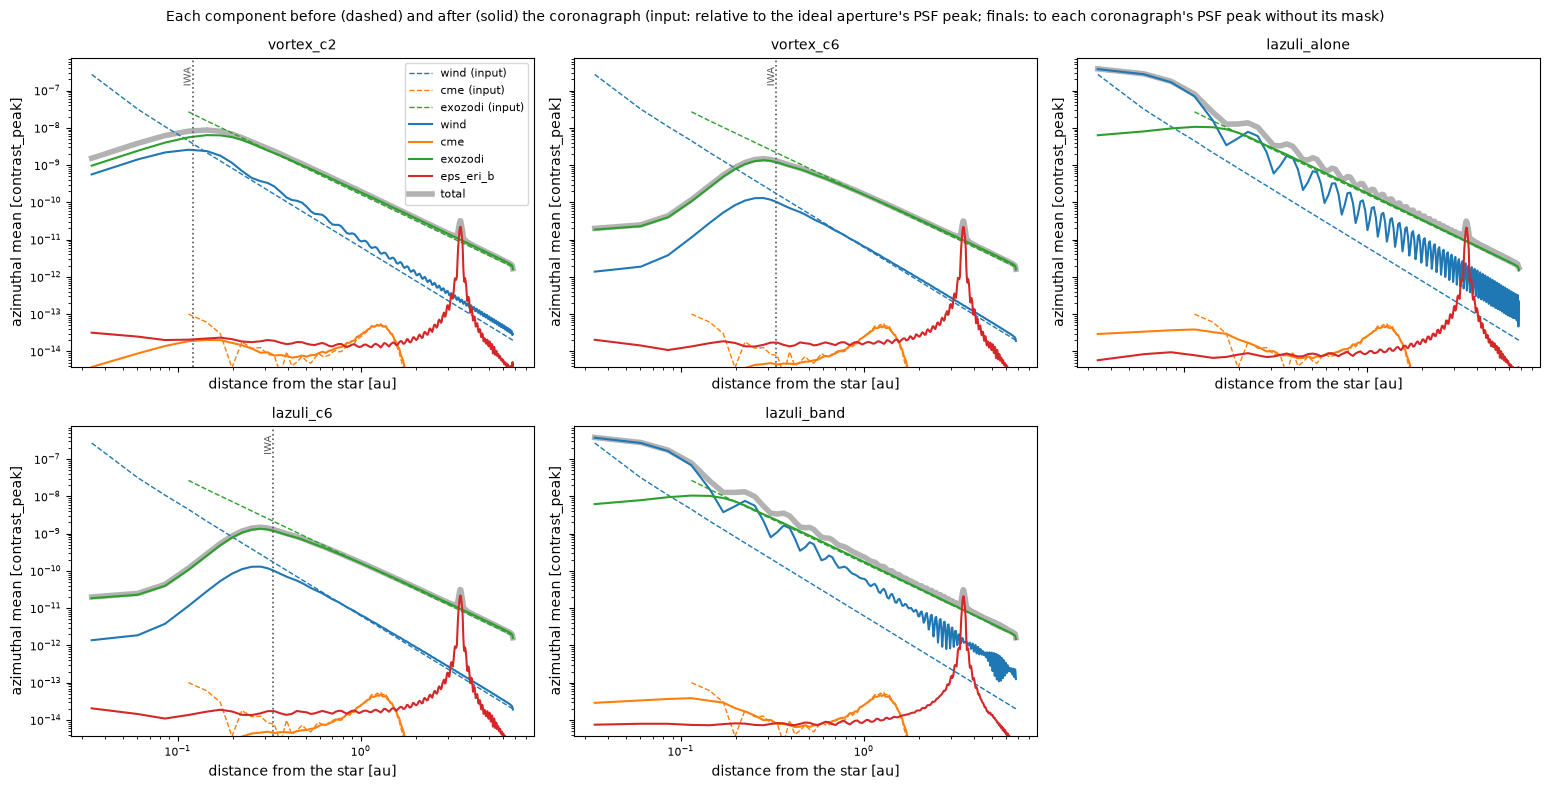

vortex_c2    IWA: 0.038 arcsec = 0.12 au
vortex_c6    IWA: 0.103 arcsec = 0.33 au
lazuli_alone IWA: none
lazuli_c6    IWA: 0.103 arcsec = 0.33 au
lazuli_band  IWA: none


In [38]:
fig = result.plot_profiles(components=True, unit="contrast_peak", axis="au")
for coronagraph in result.finals:
    iwa = result.iwa(coronagraph)                                   # arcsec, None without a coronagraph
    print("%-12s IWA: %s" % (coronagraph, "none" if iwa is None else "%.3f arcsec = %.2f au" % (iwa, iwa*eps_eri.distance)))

### Choosing what a plot shows

Every scene and result plot takes the same settings: `unit`, `log`, `log_range` (decades shown on a log scale; profiles show 3 more), `axis`, and `dpi` with `path=` to save the figure. A setting left out comes from `[display]` in the parameter file (or `Scene(display={...})`), so one line there changes every plot. Any other keyword goes to matplotlib: to `imshow` for images (e.g. `cmap="magma"`), to `plot` for curves (e.g. `lw=2`). Each plot returns its matplotlib figure, to change further.

For a figure of your own, use the data behind the plots: `result.final(coronagraph, component, unit=...)` (a final image), `result.inputs` (the input images), `result.contributions(coronagraph)` (each component's share), `result.iwa(coronagraph)` and `radial_profile(image, result.grid)` (radius in arcsec, azimuthal mean). Below: the coronagraphs' totals with 4 decades and another colour map, then the wind alone through two vortices, drawn with matplotlib.

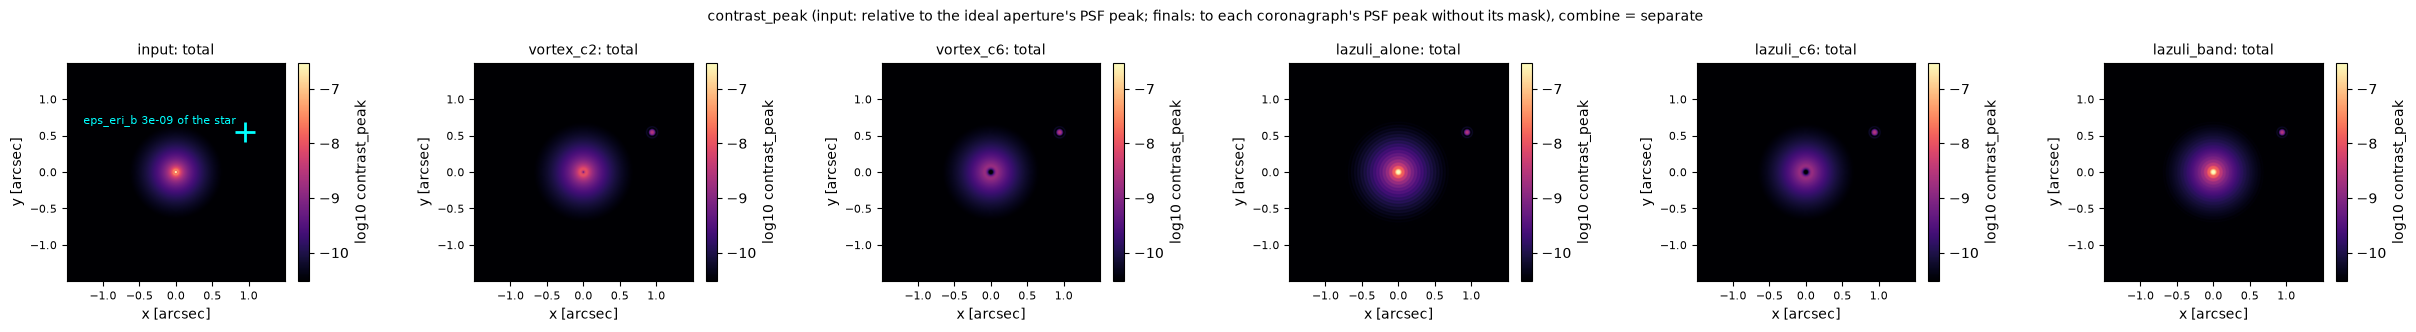

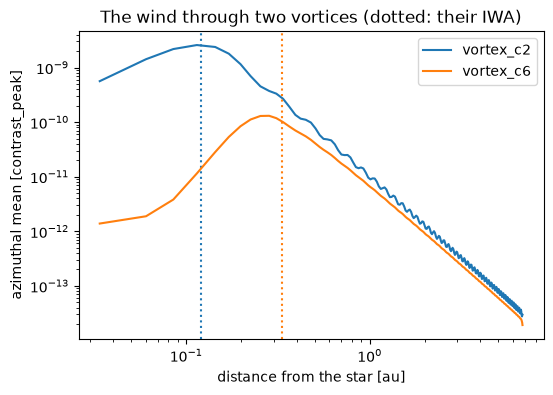

In [39]:
# The same settings in every plot; other keywords go to matplotlib
fig = result.plot(unit="contrast_peak", components=["total"], log_range=4, cmap="magma")

# A figure of your own, from the data behind the plots
import matplotlib.pyplot as plt
from toycoronagraph.scene import radial_profile
fig, ax = plt.subplots(figsize=(6, 4))
for coronagraph in ["vortex_c2", "vortex_c6"]:
    r, mean = radial_profile(result.final(coronagraph, "wind", unit="contrast_peak"), result.grid)
    line, = ax.loglog(r[1:]*eps_eri.distance, mean[1:], label=coronagraph)   # arcsec -> au; [1:]: not the star pixel
    ax.axvline(result.iwa(coronagraph)*eps_eri.distance, ls=":", color=line.get_color())
ax.set(xlabel="distance from the star [au]", ylabel="azimuthal mean [contrast_peak]",
       title="The wind through two vortices (dotted: their IWA)")
ax.legend()
plt.show()

## A time series: a CME moving outwards

`video(scene, coronagraph, component, frames)` changes one component frame by frame (each frame a dict of its settings) and writes a lossless video. Only that component is observed again for each frame: the other components' final images are reused, and the PSFs and the spatial model come from the caches, so a frame takes a fraction of a second.

A realistic CME is 1e-11 of the star's light, lost in the wind (4.7e-7). Solar coronagraphs see CMEs in **base-difference images**: each image minus one taken before the event. `difference=True` does the same: each frame minus the other components' final images, so it shows the CME alone. Here the CME's shell moves out by 3 shell thicknesses over 20 frames (`horizontal_height_factor`), through the charge-6 vortex; `log_range=3` shows the 3 decades below the first frame's peak.

In [40]:
# The CME moving outwards, through the charge-6 vortex: the frames minus the wind, the exozodi and the planet
frames = [{"horizontal_height_factor": h} for h in np.linspace(0, 3, 20)]
path, cme_frames = video(scene, "vortex:6", "cme", frames, difference=True, log_range=3)
print("Saved the video to", path)


cme through vortex_c6:   0%|          | 0/20 [00:00<?, ?it/s]


cme through vortex_c6:  85%|████████▌ | 17/20 [00:02<00:00,  8.23it/s]


cme through vortex_c6: 100%|██████████| 20/20 [00:02<00:00,  8.21it/s]


cme_vortex_c6.webm:   0%|          | 0/20 [00:00<?, ?it/s]


cme_vortex_c6.webm: 100%|██████████| 20/20 [00:04<00:00,  4.69it/s]

Saved the video to cme_vortex_c6.webm


In [41]:
from IPython.display import Video
Video(path, embed=True, html_attributes="controls loop autoplay")

## Save, load, and scene files

* `result.save(folder)` writes a **run folder**: `scene.fits` (the inputs, one extension per component), one FITS file per coronagraph (`FINAL_TOTAL` and one `FINAL_<COMPONENT>` extension each; `PEAKNORM` in its header is the contrast_peak reference), `params_used.toml` and quick-look images (`finals.png`, `contributions.png`). `Result.load(folder)` reads it back to re-plot or change units without computing again.
* `write_scene` saves a scene's images as one multi-extension FITS file; the **`scene_fits`** module reads them back as inputs (e.g. images made elsewhere).
* The same scene can come from a **parameter file** (`Scene.from_file`), whose `[[coronagraph]]` tables `observe` then uses. The planet below moves on epsilon Eri b's orbit (e = 0.07, inclination 79°). Built-in modules only: your own need `module = "..."`.
* Images from FITS files (**`fits_image`**, **`mcfost`**) are modules too: the MCFOST disk of the section above goes through the same way, on its own grid.

Expected output:
```
scene_fits round trip identical: True
```

In [42]:
# A run folder: FITS images (input and final, one extension per component), the parameters used, quick looks
folder = result.save("results/eps_eri", overwrite=True)
again = Result.load(folder)                                    # re-plot or change units without computing again

# The scene's images as one multi-extension FITS file, read back as an input module (scene_fits)
write_scene("eps_eri_scene.fits", images, scene.internal_unit, scene.grid, eps_eri, overwrite=True)
from_file = Scene(star=eps_eri, wavelength=632e-9, diameter=3.0, sampling=5, fov=3.0)
from_file.add(SceneFits(file="eps_eri_scene.fits"))
print("scene_fits round trip identical:", all(np.allclose(from_file.render(verbose=False)[n.lower()], images[n]) for n in images))

scene_fits round trip identical: True


The scene from a parameter file: the wind and the planet through Lazuli with a charge-6 vortex (the file's own `[[coronagraph]]`). The file keeps the WCC detector's own pixels (`size` and `pixel_scale`): Lazuli's PSFs have their own pupil sampling, so they are right at any pixel size (a vortex table here would warn). Then the MCFOST disk as a scene module: one image through one coronagraph is drawn as one row, the input next to the final image.

Scene: 163 x 163 px, 0.018445 arcsec/pixel (2.36 px per lambda/D at 6.32e-07 m); wind, eps_eri_b; in contrast_pixel


lazuli_c6, wind: Method: circular (auto; target symmetric: known by the wind module; PSFs symmetric: lazuli model)


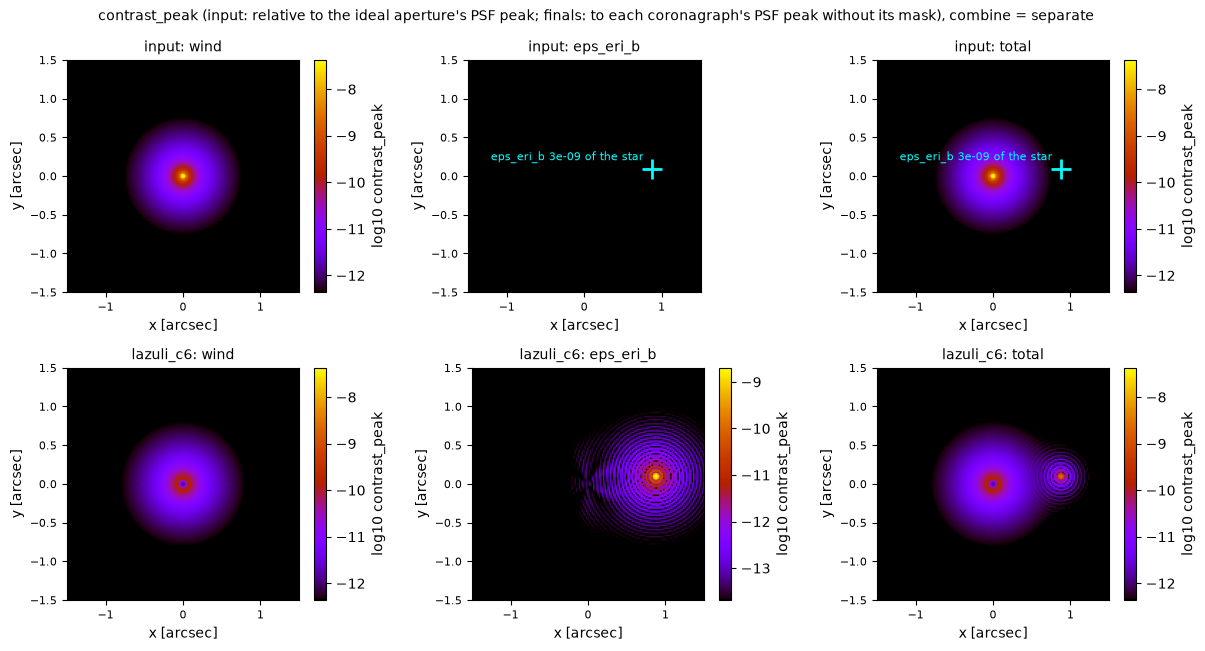

Scene: 455 x 455 px, 0.006044 arcsec/pixel (8.18 px per lambda/D at 5.75e-07 m); mcfost; in Jy/arcsec^2


Kernel size K=131 (chosen for this image before: ./kernel_vortex_c6_N455_range27.8241_lyot0.95_a9d1f175389345dd.json)


Spatial PSF model K=131: from ./model_vortex_c6_N455_range27.8241_lyot0.95_rotate_K131_40883e23a820cef3.npz


vortex_c6, mcfost: Method: spatial, rotate mode (auto; target not symmetric: asymmetry 70%, light in the corners 0% (tol 1%); PSFs symmetric: vortex model); estimated error 1.7%


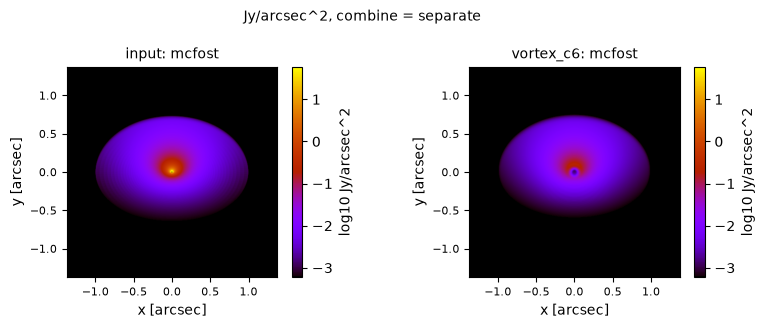

In [43]:
# The same kind of scene from a parameter file (built-in modules only; your own need module = "...")
with open("eps_eri.toml", "w") as f:
    f.write("""[observation]
wavelength = "632 nm"
diameter = 3.0
[grid]
size = 163
pixel_scale = 0.018445   # arcsec: Lazuli's WCC detector pixel
[star]
distance = 3.22
radius = 0.73
[[source]]
kind = "wind"
mdot = 6e-13
v = 400
[[source]]
kind = "planet"
name = "eps_eri_b"
mode = "moving"
pos = [1.09, 0.07, 30, 79, 0.0]   # a (arcsec), e, PA (deg), inclination (deg), time (periods)
brightness = 3e-9
brightness_unit = "contrast"
[[coronagraph]]
type = "lazuli"
charge = 6
""")
file_result = observe(Scene.from_file("eps_eri.toml"))   # the file's own [[coronagraph]] tables
fig = file_result.plot(unit="contrast_peak")

# Images from files work in scenes too: the MCFOST disk of the section above (its own grid and units)
disk_result = observe(Scene.from_file("inclined_disk.toml"), ["vortex:6"])
fig = disk_result.plot()

## The strict grid

By default every image is put on the scene's grid. With **`[grid] resample = false`** (here `Scene(..., resample=False)`) nothing is resampled to another field: images must cover the grid's field (`size` x `pixel_scale`); another resolution of the same field is still rebinned. Computed modules (wind, planets, your own) always match, since they draw on the grid. It is the safe choice when your images are made for the grid, e.g. the scene file written above.

Expected output:
```
Scene: 345 x 345 px, 0.0086906 arcsec/pixel (5 px per lambda/D at 6.32e-07 m); wind, cme, exozodi, eps_eri_b; in contrast_pixel
Problems: [grid] resample = false, but these images cover another field than the grid:
  ring_2arcsec.fits (image): 200 px of 0.01 arcsec (2 arcsec across), the grid is 345 px of 0.00869062 arcsec (2.99827 across)
  give the grid their field (for another resolution set only [grid] size, with pixel_scale = "auto"), or set [grid] resample = true
```

In [44]:
# [grid] resample = false: images must cover the grid's field; the scene file written above does
strict = Scene(star=eps_eri, wavelength=632e-9, diameter=3.0, sampling=5, fov=3.0, resample=False)
strict.add(SceneFits(file="eps_eri_scene.fits"))
strict.add(Planet(mode="polar", pos=[1.09, 30], brightness=3e-9, brightness_unit="contrast"), name="eps_eri_b")
images_strict = strict.render()

# An image of another field (2.0" across instead of 3.0") stops the run, and the message says how to fix it
n = 200
y, x = (np.indices((n, n))-(n-1)/2)*0.01                          # arcsec
ring = np.exp(-0.5*((np.hypot(x, y)-0.6)/0.05)**2)
header = fits.Header([("BUNIT", "Jy/arcsec^2"), ("PIXSCALE", 0.01), ("WAVELEN", 632e-9)])
fits.PrimaryHDU(ring, header).writeto("ring_2arcsec.fits", overwrite=True)
strict.add(FitsImage(file="ring_2arcsec.fits"))
try:
    strict.render()
except ParamError as error:
    print("Problems:", error)

Scene: 345 x 345 px, 0.0086906 arcsec/pixel (5 px per lambda/D at 6.32e-07 m); wind, cme, exozodi, eps_eri_b; in contrast_pixel
Problems: [grid] resample = false, but these images cover another field than the grid:
  ring_2arcsec.fits (image): 200 px of 0.01 arcsec (2 arcsec across), the grid is 345 px of 0.00869062 arcsec (2.99827 across)
  give the grid their field (for another resolution set only [grid] size, with pixel_scale = "auto"), or set [grid] resample = true
